# Economic narratives and consumer sentiment

**Panagiotis Housos | ph2606 | AI Applications in Finance | Final Project**

Information cutoff: October 13, 2026. Human validation is not completed; independent AI reviews are explicitly separate. Acquisition and model scoring run separately. The cells below rerun analysis from local frozen inputs. Raw datasets are excluded from Git under the established submission policy.

In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / 'src/economics.py').exists(), 'Execute from the project root.'
expected_inputs = {'data/processed/monthly_dataset.csv': '8cfeac44c5132ab25883598bf3d4a0ad84cd10f6b7f5af43b8d16e55127f9b6a', 'data/processed/media_monthly.csv': '9643fa2ad6052d7f66020737aa2d2fd65f22362d1969f1fec623549cb5fc91fa', 'outputs/tables/provider_bias.csv': '06e999b8b87368f37891f4a25c347bf63ccd3e00278a513dfcc68cb3d3efeeb9', 'data/processed/investment_prices.csv': '2c86cd2c3bcd7441b5ccf29247a90c8832d30aff8477fd622001441cfddf1401', 'data/processed/media_scores.csv': 'c8ea6ce87cf91290c688b30854cdb37ddaa9dbf62f275494593fedb15626d2ab', 'data/processed/bias_trading_prices.csv': '0f0c755611c96bf958d42b959c0875d86a11402deba719bb7578dc77afe0aff8', 'data/processed/part_b_demography.csv': '0b4242d82af61be9b506c4e417e939fd0fe8ae32d4240a47981d42624ff34703', 'data/processed/country_birth_rates_2023.csv': '58be8f95adc5bbdbdeea79189a5a30cdaa48f8829050abc2cec50a50405c334b'}
for name, expected in expected_inputs.items():
    path = ROOT / name
    assert path.exists(), f'Acquire required input: {name}'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, f'Input changed: {name}. Rerun analysis and rebuild deliverables before executing this notebook.'
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.precision', 4)

## Recompute the frozen empirical analysis

The economic feature matrix uses historical ALFRED snapshots. Media reconstruction is retrospective and subject to source selection and original-wording limitations. The package never invents missing records, exposure or human labels.

In [2]:
import subprocess, sys
for command in [['scripts/03_analyze.py'], ['-m', 'src.dynamics'], ['-m', 'src.investing', 'analyze'], ['-m', 'src.bias_trading', 'analyze'], ['scripts/08_validation_tables.py'], ['-m','src.external_validation','score'], ['-m','src.rubric_evidence'], ['-m','src.part_b_demography','build'], ['-m','src.reader_evidence'], ['-m','src.country_birth_rates','build']]:
    result = subprocess.run([sys.executable, *command], cwd=ROOT, capture_output=True, text=True)
    print(result.stdout)
    assert result.returncode == 0, result.stderr
print('Primary study and separately identified extensions recalculated from frozen inputs.')

{
  "cutoff": "2026-10-13",
  "macro_timing": "Actual ALFRED historical vintages on the first calendar day of every forecast month; within-day release time not resolved, interpret origin as end of that day.",
  "target_limitation": "Official Michigan final historical tables, not historical target vintages; partial target revision leakage cannot be excluded.",
  "gdp_treatment": "No interpolation: predictor is growth of last quarterly real GDP observation present in each vintage.",
  "interval_caution": "Approximate HAC parameter + residual intervals; empirical past-OOS-error intervals after 24 calibration observations. Report realized coverage; no guarantee under structural breaks.",
  "latest_final_forecast": {
    "month": "2026-09-01",
    "prediction_date": "2026-09-01",
    "target": "sentiment",
    "model": "M1_economic",
    "observed": 48.1,
    "prediction": 70.66545331146001,
    "gap": -22.56545331146001,
    "error": -22.56545331146001,
    "lower_95": 50.2316036338248,
  

{
  "pool_n": 80,
  "holdout_n": 44,
  "metrics": [
    {
      "model": "D_macro",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.3005264839,
      "mae": 3.498214615,
      "mean_error": 0.2859605397,
      "analysis_status": "exploratory",
      "rmse_gain_percent_vs_baseline": null,
      "comparison_baseline": null
    },
    {
      "model": "D_macro_AR",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.2226540069,
      "mae": 3.4241520681,
      "mean_error": 0.236443637,
      "analysis_status": "exploratory",
      "rmse_gain_percent_vs_baseline": null,
      "comparison_baseline": null
    },
    {
      "model": "D_macro_AR_media",
      "n": 44,
      "start": "2023-02-01T00:00:00.000",
      "end": "2026-09-01T00:00:00.000",
      "rmse": 4.2234114057,
      "mae": 3.3866487028,
      "mean_error": 0.2249447442,
      "analysis_status": "explor

                   label  net_total_return  net_cagr  max_drawdown  average_equity_weight
Macro + trend allocation          0.880100  0.055209     -0.201055               0.634109
        SPY buy-and-hold          3.537800  0.137393     -0.337173               1.000000
       Treasury-bill ETF          0.252940  0.019379     -0.002309               0.000000
             Fixed 60/40          1.801621  0.091650     -0.207803               0.600947
{
  "hac_tests": {
    "primary_minus_static": {
      "annualized_daily_intercept": -0.03480351865098805,
      "lower_95": -0.06372102984216918,
      "upper_95": -0.005886007459806919,
      "pvalue": 0.01832897913462651,
      "n": 2955,
      "market_beta": null,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    },
    "bil_relative_market_model": {
      "annualized_daily_intercept": -0.017837458040149648,
      "lower_95": -0.048388109862808365,
      "upper_95": 0.012713193782509074,
      "pvalue": 0.252476657251

                   label  net_cagr  net_total_return  max_drawdown  terminal_value_10000
            Fade the gap  0.065893          0.435196     -0.637349          14351.956134
          Follow the gap -0.257559         -0.814773     -0.890736           1852.274978
         Wait for a turn  0.059449          0.386753     -0.344259          13867.528694
      S&P 500 fund (SPY)  0.146955          1.173418     -0.244964          21734.177601
Treasury-bill fund (BIL)  0.031831          0.194127     -0.002200          11941.269090
     Always 3x up (UPRO)  0.270409          2.877175     -0.639431          38771.745866
   Always 3x down (SPXU) -0.363757         -0.922707     -0.927405            772.925422
   Half UPRO / half SPXU -0.014579         -0.079791     -0.135153           9202.092113
       60% SPY / 40% BIL  0.101960          0.732757     -0.149856          17327.571466
Fund decisions: {"Fade_gap": {"UPRO": 38, "SPXU": 29, "BIL": 1}, "Follow_gap": {"SPXU": 38, "UPRO": 29, "BIL":

              cohort   reference      model    label_type   n  matching_labels  agreement  agreement_wilson_lower_95  agreement_wilson_upper_95  macro_f1_concordance
original_review_pool annotator_a contextual ai_diagnostic 242              177   0.731405                   0.672266                   0.783312              0.707438
original_review_pool annotator_a dictionary ai_diagnostic 242              153   0.632231                   0.569854                   0.690477              0.600011
original_review_pool annotator_b contextual ai_diagnostic 243              173   0.711934                   0.652045                   0.765226              0.683871
original_review_pool annotator_b dictionary ai_diagnostic 243              156   0.641975                   0.579918                   0.699614              0.611387
 final_eligible_pool annotator_a contextual ai_diagnostic 231              169   0.731602                   0.671012                   0.784614              0.707149
 fin

     model   n  external_human_reference_accuracy  accuracy_wilson_lower  accuracy_wilson_upper  macro_f1
contextual 300                           0.536667               0.480132               0.592274  0.512678
dictionary 300                           0.510000               0.453664               0.566083  0.477747
External human reference only; the target two-human requirement remains unsatisfied.



{
  "artifacts": [
    "outputs/tables/rubric_loss_contrasts.csv",
    "outputs/tables/rubric_tone_associations.csv",
    "outputs/tables/rubric_survey_components.csv",
    "outputs/tables/rubric_economic_sensitivities.csv",
    "outputs/tables/rubric_media_sensitivities.csv",
    "outputs/tables/rubric_dynamic_sensitivities.csv",
    "outputs/tables/rubric_forecast_skill.csv",
    "outputs/tables/rubric_model_diagnostics.csv",
    "outputs/tables/rubric_power_plan.csv"
  ],
  "planning_only": {
    "standardized_effect_sd": 0.25,
    "two_sided_alpha": 0.05,
    "target_power": 0.8,
    "assumed_attrition": 0.2,
    "normal_approximation_complete_per_arm": 252,
    "complete_outcomes_per_arm": 253,
    "finite_t_power_at_complete_n": 0.801358352573639,
    "randomized_per_arm": 317,
    "arms": 3,
    "randomized_total": 951,
    "status": "prospective planning assumptions, not participant data"
  }
}



Country / aggregate  Fertility1990  Fertility2023  Birth rate1990  Birth rate2023
      United States          2.081          1.617          16.700          10.700
     United Kingdom          1.830          1.560          13.900          10.023
            Germany          1.450          1.390          11.400           8.300
             France          1.770          1.660          13.400           9.900
              Italy          1.330          1.210          10.000           6.400
              China          2.514          0.999          21.060           6.390
              India          4.045          1.975          32.569          16.146
         Bangladesh          4.506          2.163          35.141          20.353
        South Korea          1.570          0.721          15.200           4.500
              Japan          1.540          1.200          10.000           6.000
            Nigeria          6.459          4.482          44.513          32.954
              Ni

Built literature ledger, published-effects table and original AI-learning figure.



Built5chartpairs and Country_Birth_Rates_Top_100.pdf; common xaxis0–60

Primary study and separately identified extensions recalculated from frozen inputs.


## Persistence and differenced-model sensitivity

These checks were added after the primary analysis and are exploratory. ADF and KPSS have different null hypotheses; structural breaks limit either interpretation. The differenced models use the same 44 test months and a separately identified two-contrast loss-test family.

In [3]:
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_unit_root.csv'))
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_differenced_metrics.csv'))
display(pd.read_csv(ROOT / 'outputs/tables/dynamics_loss_hac.csv'))

,sample,variable,n,start,end,lag1_correlation,adf_statistic,...,kpss_statistic,kpss_pvalue_tabulated,kpss_pvalue_boundary,kpss_lags_auto,adf_null,kpss_null,interpretation
0,historical,sentiment,201,2010-01-01,2026-09-01,0.9592,-0.4018,...,0.7236,0.0114,within tabulated range,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
1,historical,unemployment,201,2010-01-01,2026-09-01,0.9363,-2.8838,...,1.2641,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
2,historical,pce_yoy,201,2010-01-01,2026-09-01,0.9824,-1.9677,...,0.7878,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
3,historical,gdp_qoq_annualized,201,2010-01-01,2026-09-01,0.5635,-4.3157,...,0.0246,0.1000,p > 0.10,1,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
4,historical,price_36m,201,2010-01-01,2026-09-01,0.9956,-1.4358,...,1.1486,0.0100,p < 0.01,9,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
5,historical,real_income_yoy,201,2010-01-01,2026-09-01,0.3700,-4.5556,...,0.0879,0.1000,p > 0.10,8,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
6,historical,media_tone_lag1,80,2020-02-01,2026-09-01,0.2231,-7.0025,...,0.1979,0.1000,p > 0.10,3,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
7,historical,delta_sentiment,200,2010-02-01,2026-09-01,0.0727,-8.8224,...,0.2467,0.1000,p > 0.10,10,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
8,common_media_pool,sentiment,80,2020-02-01,2026-09-01,0.8960,-0.7997,...,0.8270,0.0100,p < 0.01,5,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...
9,common_media_pool,unemployment,80,2020-02-01,2026-09-01,0.8189,-2.2066,...,0.5596,0.0282,within tabulated range,5,unit root,level stationarity,Exploratory diagnostics; structural breaks can invalidate a unit-r...


,model,n,start,end,rmse,mae,mean_error,analysis_status,rmse_gain_percent_vs_baseline,comparison_baseline
0,D_macro,44,2023-02-01,2026-09-01,4.3005,3.4982,0.2860,exploratory,NaN,NaN
1,D_macro_AR,44,2023-02-01,2026-09-01,4.2227,3.4242,0.2364,exploratory,NaN,NaN
2,D_macro_AR_media,44,2023-02-01,2026-09-01,4.2234,3.3866,0.2249,exploratory,-0.0179,D_macro_AR
3,D_macro_media,44,2023-02-01,2026-09-01,4.2729,3.4134,0.2692,exploratory,0.6418,D_macro


,family,augmented,baseline,n,start,end,hac_maxlags,primary_bandwidth,mean_squared_loss_difference,hac_se_mean_loss_difference,hac_pvalue_two_sided,family_size,interpretation,bh_qvalue_within_bandwidth_family
0,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,3,True,-0.2245,3.5024,0.9489,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
1,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,3,True,-1.3620,5.3445,0.7988,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
2,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,3,True,-0.4142,0.9502,0.6629,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9489
3,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,6,False,-0.2245,3.0742,0.9418,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
4,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,6,False,-1.3620,4.8012,0.7767,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
5,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,6,False,-0.4142,1.0104,0.6818,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9418
6,original_three_contrasts_bandwidth_sensitivity,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,12,False,-0.2245,2.7289,0.9344,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
7,original_three_contrasts_bandwidth_sensitivity,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,12,False,-1.3620,3.5679,0.7027,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
8,original_three_contrasts_bandwidth_sensitivity,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,12,False,-0.4142,1.0795,0.7012,3,Exploratory nested-model loss comparison; limited sample; not causal,0.9344
9,exploratory_differenced_two_contrasts,D_macro_media,D_macro,44,2023-02-01,2026-09-01,3,True,-0.2366,0.7519,0.7530,2,Exploratory nested-model loss comparison; limited sample; not causal,0.9910


## Independent AI diagnostic: class and source concordance

These are AI development references, not human ground truth. The original pool has 300 items; final-corpus eligibility and mixed/uncertain exclusions are explicit. Small source/class cells have unstable estimates. Required human validation remains pending.

In [4]:
ai = json.loads((ROOT/'outputs/ai_diagnostic_validation_metrics.json').read_text())
display(pd.Series({k: ai.get(k) for k in ['label_type','completed_independent_pairs','tone_agreement','tone_cohens_kappa','annotation_pool_final_eligible_n','annotation_pool_final_excluded_n','human_specific_requirement_satisfied']}))
for name in ['cohorts','model_concordance','class_concordance','source_concordance','confusion_matrices','dimension_agreement']:
    print('Explicit original and final populations:', name)
    display(pd.read_csv(ROOT / ('outputs/tables/validation_'+name+'.csv')))

label_type                              ai_diagnostic
completed_independent_pairs                       300
tone_agreement                                   0.92
tone_cohens_kappa                              0.8895
annotation_pool_final_eligible_n                  277
annotation_pool_final_excluded_n                   23
human_specific_requirement_satisfied            False
dtype: object

Explicit original and final populations: cohorts


,cohort,reference,paired_items,three_class_reference_n,excluded_mixed_or_uncertain_n,negative,neutral,positive,mixed,cannot determine
0,original_review_pool,annotator_a,300,242,58,121,41,80,38,20
1,original_review_pool,annotator_b,300,243,57,125,41,77,41,16
2,final_eligible_pool,annotator_a,277,231,46,114,39,78,38,8
3,final_eligible_pool,annotator_b,277,232,45,118,39,75,40,5


Explicit original and final populations: model_concordance


,cohort,reference,model,label_type,n,matching_labels,agreement,agreement_wilson_lower_95,agreement_wilson_upper_95,macro_f1_concordance
0,original_review_pool,annotator_a,contextual,ai_diagnostic,242,177,0.7314,0.6723,0.7833,0.7074
1,original_review_pool,annotator_a,dictionary,ai_diagnostic,242,153,0.6322,0.5699,0.6905,0.6000
2,original_review_pool,annotator_b,contextual,ai_diagnostic,243,173,0.7119,0.6520,0.7652,0.6839
3,original_review_pool,annotator_b,dictionary,ai_diagnostic,243,156,0.6420,0.5799,0.6996,0.6114
4,final_eligible_pool,annotator_a,contextual,ai_diagnostic,231,169,0.7316,0.6710,0.7846,0.7071
5,final_eligible_pool,annotator_a,dictionary,ai_diagnostic,231,144,0.6234,0.5594,0.6834,0.5905
6,final_eligible_pool,annotator_b,contextual,ai_diagnostic,232,165,0.7112,0.6498,0.7657,0.6826
7,final_eligible_pool,annotator_b,dictionary,ai_diagnostic,232,147,0.6336,0.5699,0.6930,0.6025


...

,cohort,reference,model,label_type,source,n,matching_labels,agreement,agreement_wilson_lower_95,agreement_wilson_upper_95,macro_f1_concordance
0,original_review_pool,annotator_a,contextual,ai_diagnostic,Associated Press,35,25,0.7143,0.5495,0.8367,0.6919
1,original_review_pool,annotator_a,contextual,ai_diagnostic,Colorado Sun,37,30,0.8108,0.6580,0.9052,0.7821
2,original_review_pool,annotator_a,contextual,ai_diagnostic,Gothamist,31,24,0.7742,0.6019,0.8860,0.7643
3,original_review_pool,annotator_a,contextual,ai_diagnostic,Hacker News,36,27,0.7500,0.5893,0.8625,0.7355
4,original_review_pool,annotator_a,contextual,ai_diagnostic,NPR,36,27,0.7500,0.5893,0.8625,0.7394
5,original_review_pool,annotator_a,contextual,ai_diagnostic,Reuters,36,24,0.6667,0.5033,0.7979,0.6257
6,original_review_pool,annotator_a,contextual,ai_diagnostic,Texas Tribune,31,20,0.6452,0.4695,0.7888,0.5556
7,original_review_pool,annotator_a,dictionary,ai_diagnostic,Associated Press,35,24,0.6857,0.5202,0.8145,0.6646
8,original_review_pool,annotator_a,dictionary,ai_diagnostic,Colorado Sun,37,22,0.5946,0.4349,0.7365,0.5722
9,original_review_pool,annotator_a,dictionary,ai_diagnostic,Gothamist,31,15,0.4839,0.3197,0.6516,0.4593


Explicit original and final populations: confusion_matrices


,cohort,reference,model,label_type,reference_class,model_class,n
0,original_review_pool,annotator_a,contextual,ai_diagnostic,negative,negative,88
1,original_review_pool,annotator_a,contextual,ai_diagnostic,negative,neutral,29
2,original_review_pool,annotator_a,contextual,ai_diagnostic,negative,positive,4
3,original_review_pool,annotator_a,contextual,ai_diagnostic,neutral,negative,2
4,original_review_pool,annotator_a,contextual,ai_diagnostic,neutral,neutral,33
...,...,...,...,...,...,...,...
67,final_eligible_pool,annotator_b,dictionary,ai_diagnostic,neutral,neutral,24
68,final_eligible_pool,annotator_b,dictionary,ai_diagnostic,neutral,positive,13
69,final_eligible_pool,annotator_b,dictionary,ai_diagnostic,positive,negative,8
70,final_eligible_pool,annotator_b,dictionary,ai_diagnostic,positive,neutral,21


Explicit original and final populations: dimension_agreement


,cohort,dimension,n,agreement
0,original_review_pool,emotional_wording,300,0.9100
1,original_review_pool,frame_price_level,300,0.9700
2,original_review_pool,frame_inflation_rate,300,0.9767
3,original_review_pool,frame_household,300,0.9067
4,original_review_pool,frame_national,300,0.8433
5,original_review_pool,frame_forecast,300,0.9267
6,original_review_pool,frame_current,300,0.8967
7,original_review_pool,political_actor,300,0.9567
8,original_review_pool,political_attribution,300,0.9133


## Political-name and source-label stress tests

The original text is held constant except for the specified change. Changed names can change meaning. Class switches do not prove political discrimination or factual bias.

In [5]:
media_summary = json.loads((ROOT / 'outputs/media_summary.json').read_text())
display(pd.DataFrame(media_summary['perturbation']['variant_comparisons']))
print('Source-prefix paired mean absolute tone difference:', media_summary['perturbation']['source_pair_mean_absolute_delta'])
print('Factual-calibration status:', media_summary.get('factual_calibration'))

,test,n,mean_absolute_tone_delta,class_switch_rate
0,political_name_swap,100,0.0760,0.05
1,source_prefix_Gothamist,100,0.1021,0.12
2,source_prefix_Reuters,100,0.0830,0.12


Source-prefix paired mean absolute tone difference: 0.05627288064146129
Factual-calibration status: {'numeric_eligible_titles': 313, 'purposive_same_release_day_values_checked': 8, 'numerically_aligned': 8, 'population_factual_error_rate': None, 'fully_verified_definition_period_and_intraday_vintage_claims': 0, 'interpretation': 'Eight purposive unemployment-title percentages match archived official release values; this is numeric alignment, not an estimate of overall factual accuracy. Most titles omit precise definition or period; RSS intraday timestamps are unreliable. No factual-error rate is estimated.', 'checks_path': 'data/processed/factual_calibration_checks.csv', 'benchmarks_path': 'data/raw/media/official_claim_benchmarks.json'}


## External human-consensus transfer benchmark

Financial PhraseBank company/investor sentences differ from US economic titles. The frozen class-balanced 300 examples and unknown training overlap prevent claims of a pristine holdout. These are published human labels, not two new annotators for this project. Target-domain human validation remains incomplete.

In [6]:
for name in ['models','classes','confusion']:
    display(pd.read_csv(ROOT/('outputs/tables/external_validation_'+name+'.csv')))
external = json.loads((ROOT/'outputs/tables/external_validation_summary.json').read_text())
print('Limitations:', *external['limitations'], sep='\n- ')
assert external['human_specific_requirement_satisfied'] is False

,model,n,external_human_reference_accuracy,accuracy_wilson_lower,accuracy_wilson_upper,macro_f1
0,contextual,300,0.5367,0.4801,0.5923,0.5127
1,dictionary,300,0.5100,0.4537,0.5661,0.4777


,model,human_class,precision,recall,f1,support
0,contextual,negative,0.9459,0.35,0.5109,100
1,contextual,neutral,0.4181,0.97,0.5843,100
2,contextual,positive,0.9355,0.29,0.4427,100
3,dictionary,negative,0.5758,0.19,0.2857,100
4,dictionary,neutral,0.5566,0.59,0.5728,100
5,dictionary,positive,0.4658,0.75,0.5747,100


,model,human_class,predicted_class,n
0,contextual,negative,negative,35
1,contextual,negative,neutral,65
2,contextual,negative,positive,0
3,contextual,neutral,negative,1
4,contextual,neutral,neutral,97
5,contextual,neutral,positive,2
6,contextual,positive,negative,1
7,contextual,positive,neutral,70
8,contextual,positive,positive,29
9,dictionary,negative,negative,19


Limitations:
- External company/investor-perspective sentences, not target economic headlines.
- Unanimous balanced subset changes difficulty and prevalence.
- Training/pretraining overlap is unknown; not claimed to be unseen model data.
- Does not validate framing, factual accuracy, ideology, provider bars or consumer effects.
- Does not replace two independent human annotators on the project corpus.
- Wilson ranges are descriptive and do not account for unknown sentence/source clustering.


## Statistical evidence and prospective power

Full-history coefficient associations, chronological forecast comparisons and sample-size planning are different estimands. The planned experiment has not been run.

In [7]:
for name in ['loss_contrasts','tone_associations','survey_components','economic_sensitivities','media_sensitivities','dynamic_sensitivities','forecast_skill','power_plan']:
    print(name)
    display(pd.read_csv(ROOT/('outputs/tables/rubric_'+name+'.csv')))

loss_contrasts


,augmented,baseline,n,start,end,baseline_rmse,augmented_rmse,...,hac_se_mean_loss_difference,loss_difference_lower_95,loss_difference_upper_95,hac_pvalue_two_sided,hac_maxlags,units,bh_qvalue_existing_three_test_family
0,M2_economic_media,M1_economic,44,2023-02-01,2026-09-01,11.8547,11.8452,...,3.5024,-7.0891,6.6401,0.9489,3,mean squared survey-index points; negative favors augmented model,0.9489
1,M3_economic_media_controls,M1_controls,44,2023-02-01,2026-09-01,12.0067,11.9498,...,5.3445,-11.8371,9.1131,0.7988,3,mean squared survey-index points; negative favors augmented model,0.9489
2,AR_macro_media,AR_macro,44,2023-02-01,2026-09-01,4.6617,4.6171,...,0.9502,-2.2765,1.4480,0.6629,3,mean squared survey-index points; negative favors augmented model,0.9489


tone_associations


,sample,model,variable,coefficient,hac_se,hac_pvalue,lower_95,upper_95,bh_qvalue,effect_for_tone_plus_0_1,effect_lower_95,effect_upper_95,n,interpretation
0,common_media_history,M2_economic_media,media_tone_lag1,16.6040,14.2823,0.2450,-11.3888,44.5969,0.3710,1.6604,-1.1389,4.4597,80,Full-history fitted association; tone shift 0.1; HAC(3); not an OO...
1,common_media_history,M3_economic_media_controls,media_tone_lag1,18.5392,13.8293,0.1801,-8.5658,45.6442,0.2982,1.8539,-0.8566,4.5644,80,Full-history fitted association; tone shift 0.1; HAC(3); not an OO...
2,common_media_history,AR_macro_media,media_tone_lag1,9.7061,6.4311,0.1312,-2.8986,22.3108,0.2484,0.9706,-0.2899,2.2311,80,Full-history fitted association; tone shift 0.1; HAC(3); not an OO...


survey_components


...

,model,n,start,end,rmse,mae,mean_error,analysis_status,rmse_gain_percent_vs_baseline,comparison_baseline,status
0,D_macro,44,2023-02-01T00:00:00.000,2026-09-01T00:00:00.000,4.3005,3.4982,0.2860,exploratory,NaN,NaN,exploratory sensitivity added after the frozen primary analysis; n...
1,D_macro_AR,44,2023-02-01T00:00:00.000,2026-09-01T00:00:00.000,4.2227,3.4242,0.2364,exploratory,NaN,NaN,exploratory sensitivity added after the frozen primary analysis; n...
2,D_macro_AR_media,44,2023-02-01T00:00:00.000,2026-09-01T00:00:00.000,4.2234,3.3866,0.2249,exploratory,-0.0179,D_macro_AR,exploratory sensitivity added after the frozen primary analysis; n...
3,D_macro_media,44,2023-02-01T00:00:00.000,2026-09-01T00:00:00.000,4.2729,3.4134,0.2692,exploratory,0.6418,D_macro,exploratory sensitivity added after the frozen primary analysis; n...


forecast_skill


,sample,model,n,start,end,rmse,mse_ratio_to_persistence,oos_skill_vs_persistence,interpretation
0,common_historical_oos,AR1,141,2015-01-01,2026-09-01,4.3019,1.0204,-0.0204,Predictive skill against repeat-last-month; not causal explained v...
1,common_historical_oos,AR_macro,141,2015-01-01,2026-09-01,4.5925,1.1629,-0.1629,Predictive skill against repeat-last-month; not causal explained v...
2,common_historical_oos,M1_GDP_yoy,141,2015-01-01,2026-09-01,12.1526,8.1426,-7.1426,Predictive skill against repeat-last-month; not causal explained v...
3,common_historical_oos,M1_controls,141,2015-01-01,2026-09-01,11.0081,6.6812,-5.6812,Predictive skill against repeat-last-month; not causal explained v...
4,common_historical_oos,M1_economic,141,2015-01-01,2026-09-01,12.3451,8.4027,-7.4027,Predictive skill against repeat-last-month; not causal explained v...
5,common_historical_oos,M1_method_control,141,2015-01-01,2026-09-01,7.9751,3.5067,-2.5067,Predictive skill against repeat-last-month; not causal explained v...
6,common_historical_oos,M1_rolling60,141,2015-01-01,2026-09-01,9.9602,5.4697,-4.4697,Predictive skill against repeat-last-month; not causal explained v...
7,common_historical_oos,M1_seasonality,141,2015-01-01,2026-09-01,12.3841,8.4557,-7.4557,Predictive skill against repeat-last-month; not causal explained v...
8,common_historical_oos,Persistence,141,2015-01-01,2026-09-01,4.2588,1.0000,0.0000,Predictive skill against repeat-last-month; not causal explained v...
9,common_media_oos,AR1,44,2023-02-01,2026-09-01,4.3232,1.0240,-0.0240,Predictive skill against repeat-last-month; not causal explained v...


power_plan


,standardized_effect_sd,two_sided_alpha,target_power,assumed_attrition,normal_approximation_complete_per_arm,complete_outcomes_per_arm,finite_t_power_at_complete_n,randomized_per_arm,arms,randomized_total,status
0,0.20,0.05,0.8,0.2,393,394,0.8006,493,3,1479,"prospective planning assumptions, not participant data"
1,0.25,0.05,0.8,0.2,252,253,0.8014,317,3,951,"prospective planning assumptions, not participant data"
2,0.30,0.05,0.8,0.2,175,176,0.8014,220,3,660,"prospective planning assumptions, not participant data"


## Part B source data and published summaries

Demography measures births, not cognition. The AI learning chart transcribes published regression summaries; it is not a new participant-level analysis. The manifesto is an argument distinct from Part A estimates.

In [8]:
display(pd.read_csv(ROOT/'outputs/tables/part_b_demography_comparison.csv'))
with pd.option_context('display.max_rows', 100):
    display(pd.read_csv(ROOT/'outputs/tables/country_birth_rates_top100.csv'))
display(pd.read_csv(ROOT/'outputs/tables/reader_ai_published_effects.csv'))
display(pd.read_csv(ROOT/'outputs/tables/reader_attention_published.csv'))
display(pd.read_csv(ROOT/'outputs/tables/reader_evidence_sources.csv'))

,entity,entity_name,entity_type,fertility_births_per_woman_1990,births_per_1000_people_1990,fertility_births_per_woman_2023,births_per_1000_people_2023,fertility_births_per_woman_change,births_per_1000_people_change
0,USA,United States,country,2.0810,16.7000,1.6165,10.7000,-0.4645,-6.0000
1,GBR,United Kingdom,country,1.8300,13.9000,1.5600,10.0230,-0.2700,-3.8770
2,DEU,Germany,country,1.4500,11.4000,1.3900,8.3000,-0.0600,-3.1000
3,FRA,France,country,1.7700,13.4000,1.6600,9.9000,-0.1100,-3.5000
4,ITA,Italy,country,1.3300,10.0000,1.2100,6.4000,-0.1200,-3.6000
5,CHN,China,country,2.5140,21.0600,0.9990,6.3900,-1.5150,-14.6700
6,IND,India,country,4.0450,32.5690,1.9750,16.1460,-2.0700,-16.4230
7,BGD,Bangladesh,country,4.5060,35.1410,2.1630,20.3530,-2.3430,-14.7880
8,KOR,South Korea,country,1.5700,15.2000,0.7210,4.5000,-0.8490,-10.7000
9,JPN,Japan,country,1.5400,10.0000,1.2000,6.0000,-0.3400,-4.0000


,rank,iso3,country,year,display_country,births_per_1000_people,region,income_group
0,1,CAF,Central African Republic,2023,Central African Republic,46.358,Sub-Saharan Africa,Low income
1,2,SOM,"Somalia, Fed. Rep.",2023,"Somalia, Fed. Rep.",42.964,Sub-Saharan Africa,Low income
2,3,TCD,Chad,2023,Chad,42.396,Sub-Saharan Africa,Low income
3,4,NER,Niger,2023,Niger,41.892,Sub-Saharan Africa,Low income
4,5,COD,"Congo, Dem. Rep.",2023,DR Congo,41.305,Sub-Saharan Africa,Low income
5,6,MLI,Mali,2023,Mali,40.029,Sub-Saharan Africa,Low income
6,7,AGO,Angola,2023,Angola,37.588,Sub-Saharan Africa,Lower middle income
7,8,MOZ,Mozambique,2023,Mozambique,37.486,Sub-Saharan Africa,Low income
8,9,AFG,Afghanistan,2023,Afghanistan,35.437,"Middle East, North Africa, Afghanistan & Pakistan",Low income
9,10,TZA,Tanzania,2023,Tanzania,35.222,Sub-Saharan Africa,Lower middle income


,tool,outcome,coefficient,clustered_se,control_mean,lower_normal_95,upper_normal_95,effect_relative_to_control_percent,source_id
0,Standard AI assistant,assisted_practice,0.137,0.031,0.284,0.0762,0.1978,48.2394,B5
1,Hint-based AI tutor,assisted_practice,0.361,0.032,0.284,0.2983,0.4237,127.1127,B5
2,Standard AI assistant,unassisted_test,-0.054,0.022,0.321,-0.0971,-0.0109,-16.8224,B5
3,Hint-based AI tutor,unassisted_test,-0.004,0.013,0.321,-0.0295,0.0215,-1.2461,B5


,year,top50_hashtag_mean_hours,source_id
0,2013,17.5,B6
1,2016,11.9,B6


,id,source,scope_and_boundary,primary_url
0,B1,Pietschnig & Voracek (2015),"Historical IQ-test gains; 271 samples, almost 4 million participan...",https://doi.org/10.1177/1745691615577701
1,B2,Bratsberg & Rogeberg (2018),Norwegian male cohorts 1962-1991; within-family estimates recover ...,https://doi.org/10.1073/pnas.1718793115
2,B3,Kong et al. (2017),Icelandic educational-attainment polygenic score associated with l...,https://doi.org/10.1073/pnas.1612113114
3,B4,Mani et al. (2013),Experiments on financial concerns and within-farmer pre/post-harve...,https://doi.org/10.1126/science.1238041
4,B5,"Bastani et al. (2025), Table 1",Classroom-randomized Turkish high-school mathematics study. Publis...,https://doi.org/10.1073/pnas.2422633122
5,B6,Lorenz-Spreen et al. (2019),Twitter top-50 hashtag residence time: 17.5 hours in 2013 and 11.9...,https://doi.org/10.1038/s41467-019-09311-w
6,B7,Pennycook & Rand (2022),"20 US accuracy-prompt experiments, N=26,863; false-news sharing in...",https://doi.org/10.1038/s41467-022-30073-5
7,B8,"UNFPA (2025), State of World Population",14-country survey: financial constraints affected desired family s...,https://www.unfpa.org/swp2025
8,B9,"UC Berkeley, Understanding Evolution (2020 update)",Evolution does not have a universal upward or downward direction d...,https://evolution.berkeley.edu/evolution-101/the-big-issues/trends...
9,B10,"World Bank, World Development Indicators",Country/world/income-aggregate fertility and crude birth rates. Fr...,https://data.worldbank.org/indicator/SP.DYN.TFRT.IN


## News-provider comparison: matched official releases

A separate supplemental sample includes CNBC and Fox brands. The provider bars use a common set of releases and a defined peer reference. This is a relative negative-framing proxy, not a factual or ideological rating. The original forecast corpus and 300-title AI review remain separate; the new providers do not have independent human validation.

In [9]:
provider_table = pd.read_csv(ROOT / 'outputs/tables/provider_bias.csv')
display(provider_table)
provider_summary = json.loads((ROOT / 'outputs/tables/provider_bias_summary.json').read_text())
display(pd.Series(provider_summary, name='provider_comparison_protocol'))

,provider,bias_pp,lower_95,upper_95,raw_percentile_lower_95,raw_percentile_upper_95,n_titles,...,one_hash_title_bias_pp,event_bootstrap_lower_95,event_bootstrap_upper_95,coverage,same_common_events,comparison_status,ci_contains_zero
0,Associated Press,NaN,NaN,NaN,NaN,NaN,14,...,NaN,NaN,NaN,0.7222,False,outside_main_common_support_no_comparable_bar,NaN
1,Bloomberg,20.8333,-1.6667,55.0000,-1.6667,55.0000,15,...,2.0000e+01,-1.6667,55.0000,0.3333,True,main_common_event_panel,True
2,CNBC,-9.1667,-19.1667,-0.8333,-19.1667,-0.8333,15,...,-5.9212e-16,-19.1667,-0.8333,0.3333,True,main_common_event_panel,False
3,CNN,0.8333,-10.0000,14.1667,-10.0000,14.1667,9,...,-5.9212e-16,-10.0000,14.1667,0.3333,True,main_common_event_panel,True
4,Fox Business,5.8333,-6.6667,19.1667,-6.6667,19.1667,15,...,-5.9212e-16,-6.6667,19.1667,0.3333,True,main_common_event_panel,True
5,Fox News,-12.5000,-28.3333,-0.8333,-28.3333,-0.8333,8,...,-2.0000e+01,-28.3333,-0.8333,0.3333,True,main_common_event_panel,False
6,NPR,NaN,NaN,NaN,NaN,NaN,19,...,NaN,NaN,NaN,0.7222,False,outside_main_common_support_no_comparable_bar,NaN
7,Reuters,NaN,NaN,NaN,NaN,NaN,23,...,NaN,NaN,NaN,0.8889,False,outside_main_common_support_no_comparable_bar,NaN
8,Wall Street Journal,-5.8333,-12.5000,-0.8333,-12.5000,-0.8333,10,...,-5.9212e-16,-12.5000,-0.8333,0.3333,True,main_common_event_panel,False


status                                                                                                    complete
metric_name                                               same-event relative negative framing (percentage points)
formula                                      100 * mean_e[negative-title share(provider,e) - mean_other_provide...
interpretation                               Higher means more sampled titles classified negative than same-eve...
interval_interpretation                      Conditional95% month-resampling stability ranges for this fixed sa...
affiliation_note                             Fox News and Fox Business are separate queried brands with shared ...
not_measured                                 [factual inaccuracy, partisan or ideological bias, intent, audienc...
mode                                                                          identical_common_events_equal_weight
main_providers                                 [CNBC, Fox News, Fox Business, CN

## Retrospective investment extension (October 17)

The primary macro/trend rule was fixed before performance calculation; the simpler monthly 60% SPY / 40% BIL benchmark is preferred after the comparison. Neither is an untouched holdout. Costs include entry, exit and both traded legs. Gap and media overlays use retrospective inputs. All 44 gaps are negative; this is exposure, not demonstrated timing.

In [10]:
investment = json.loads((ROOT / 'outputs/tables/investment_summary.json').read_text())
performance = pd.read_csv(ROOT / 'outputs/tables/investment_metrics.csv')
display(performance.loc[performance.cost_bps.eq(10)])
print('Full-period cost sensitivity:')
display(performance.loc[performance['sample'].eq('full'), ['model','cost_bps','net_cagr','max_drawdown','annual_gross_turnover']])
print('Primary HAC diagnostics:')
display(pd.DataFrame(investment['hac_tests']).T)
print('Original two-test overlay family (unadjusted for exposure):')
display(pd.DataFrame(investment['overlay_tests']))
print('Post-result exposure diagnosis:')
print(json.dumps(investment['exposure_diagnostics'], indent=2))
print(investment['practical_conclusion'])

,sample,model,label,cost_bps,allocation_periods,start,end,...,net_cagr,volatility,max_drawdown,average_equity_weight,annual_gross_turnover,bil_relative_sharpe,terminal_value_10000
4,full,Macro_trend_80_20,Macro + trend allocation,10,141,2015-01-02,2026-10-02,...,0.0552,0.0955,-0.2011,0.6341,3.0866,0.4085,18801.0005
5,full,SPY_hold,SPY buy-and-hold,10,141,2015-01-02,2026-10-02,...,0.1374,0.1753,-0.3372,1.0000,0.1702,0.7131,45377.9997
6,full,BIL_hold,Treasury-bill ETF,10,141,2015-01-02,2026-10-02,...,0.0194,0.0027,-0.0023,0.0000,0.1702,-0.4131,12529.3950
7,full,Static_60_40,Fixed 60/40,10,141,2015-01-02,2026-10-02,...,0.0917,0.1034,-0.2078,0.6009,0.3705,0.7138,28016.2076
18,common_44,Macro_trend_80_20,Macro + trend allocation,10,44,2023-02-02,2026-10-02,...,0.1231,0.0949,-0.0836,0.6924,3.8789,0.8043,15299.5329
19,common_44,SPY_hold,SPY buy-and-hold,10,44,2023-02-02,2026-10-02,...,0.1970,0.1486,-0.1876,1.0000,0.5457,0.9872,19321.8116
20,common_44,BIL_hold,Treasury-bill ETF,10,44,2023-02-02,2026-10-02,...,0.0449,0.0025,-0.0010,0.0000,0.5457,-0.7406,11746.8588
21,common_44,Static_60_40,Fixed 60/40,10,44,2023-02-02,2026-10-02,...,0.1353,0.0882,-0.1133,0.6011,0.7045,0.9805,15918.5193
22,common_44,Gap_overlay,Exploratory gap tilt,10,44,2023-02-02,2026-10-02,...,0.1382,0.1082,-0.1026,0.7923,3.8448,0.8415,16067.6806
23,common_44,Media_overlay,Exploratory media tilt,10,44,2023-02-02,2026-10-02,...,0.1080,0.0825,-0.0712,0.5949,4.0147,0.7470,14560.2066


Full-period cost sensitivity:


,model,cost_bps,net_cagr,max_drawdown,annual_gross_turnover
0,Macro_trend_80_20,0,0.0585,-0.1953,3.0883
1,SPY_hold,0,0.1376,-0.3372,0.1702
2,BIL_hold,0,0.0196,-0.0021,0.1702
3,Static_60_40,0,0.0921,-0.2078,0.3706
4,Macro_trend_80_20,10,0.0552,-0.2011,3.0866
5,SPY_hold,10,0.1374,-0.3372,0.1702
6,BIL_hold,10,0.0194,-0.0023,0.1702
7,Static_60_40,10,0.0917,-0.2078,0.3705
8,Macro_trend_80_20,25,0.0503,-0.2096,3.0839
9,SPY_hold,25,0.1371,-0.3372,0.1700


Primary HAC diagnostics:


,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method
primary_minus_static,-0.0348,-0.0637,-0.0059,0.0183,2955,None,OLS HAC(21); annualized arithmetic daily intercept
bil_relative_market_model,-0.0178,-0.0484,0.0127,0.2525,2955,0.4542,OLS HAC(21); annualized arithmetic daily intercept


Original two-test overlay family (unadjusted for exposure):


,model,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method,bh_qvalue
0,Gap_overlay,0.0148,0.0020,0.0275,0.0233,920,None,OLS HAC(21); annualized arithmetic daily intercept,0.0233
1,Media_overlay,-0.0147,-0.0272,-0.0021,0.0223,920,None,OLS HAC(21); annualized arithmetic daily intercept,0.0233


Post-result exposure diagnosis:
{
  "status": "post-result explanatory diagnostics; conditional HAC inference, not an additional confirmatory family",
  "gap_negative_origins": 44,
  "media_negative_origins": 43,
  "origins": 44,
  "beta_adjusted_overlay_differences": [
    {
      "model": "Gap_overlay",
      "annualized_daily_intercept": 0.0001776593035039356,
      "lower_95": -2.899781088285041e-05,
      "upper_95": 0.0003843164178907216,
      "pvalue": 0.0919992162763555,
      "n": 920,
      "market_beta": 0.09910694116864897,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    },
    {
      "model": "Media_overlay",
      "annualized_daily_intercept": -0.0005203498320996874,
      "lower_95": -0.002305944622293636,
      "upper_95": 0.0012652449580942615,
      "pvalue": 0.5678886808357619,
      "n": 920,
      "market_beta": -0.09601121303001092,
      "method": "OLS HAC(21); annualized arithmetic daily intercept"
    }
  ],
  "interpretation": "All n

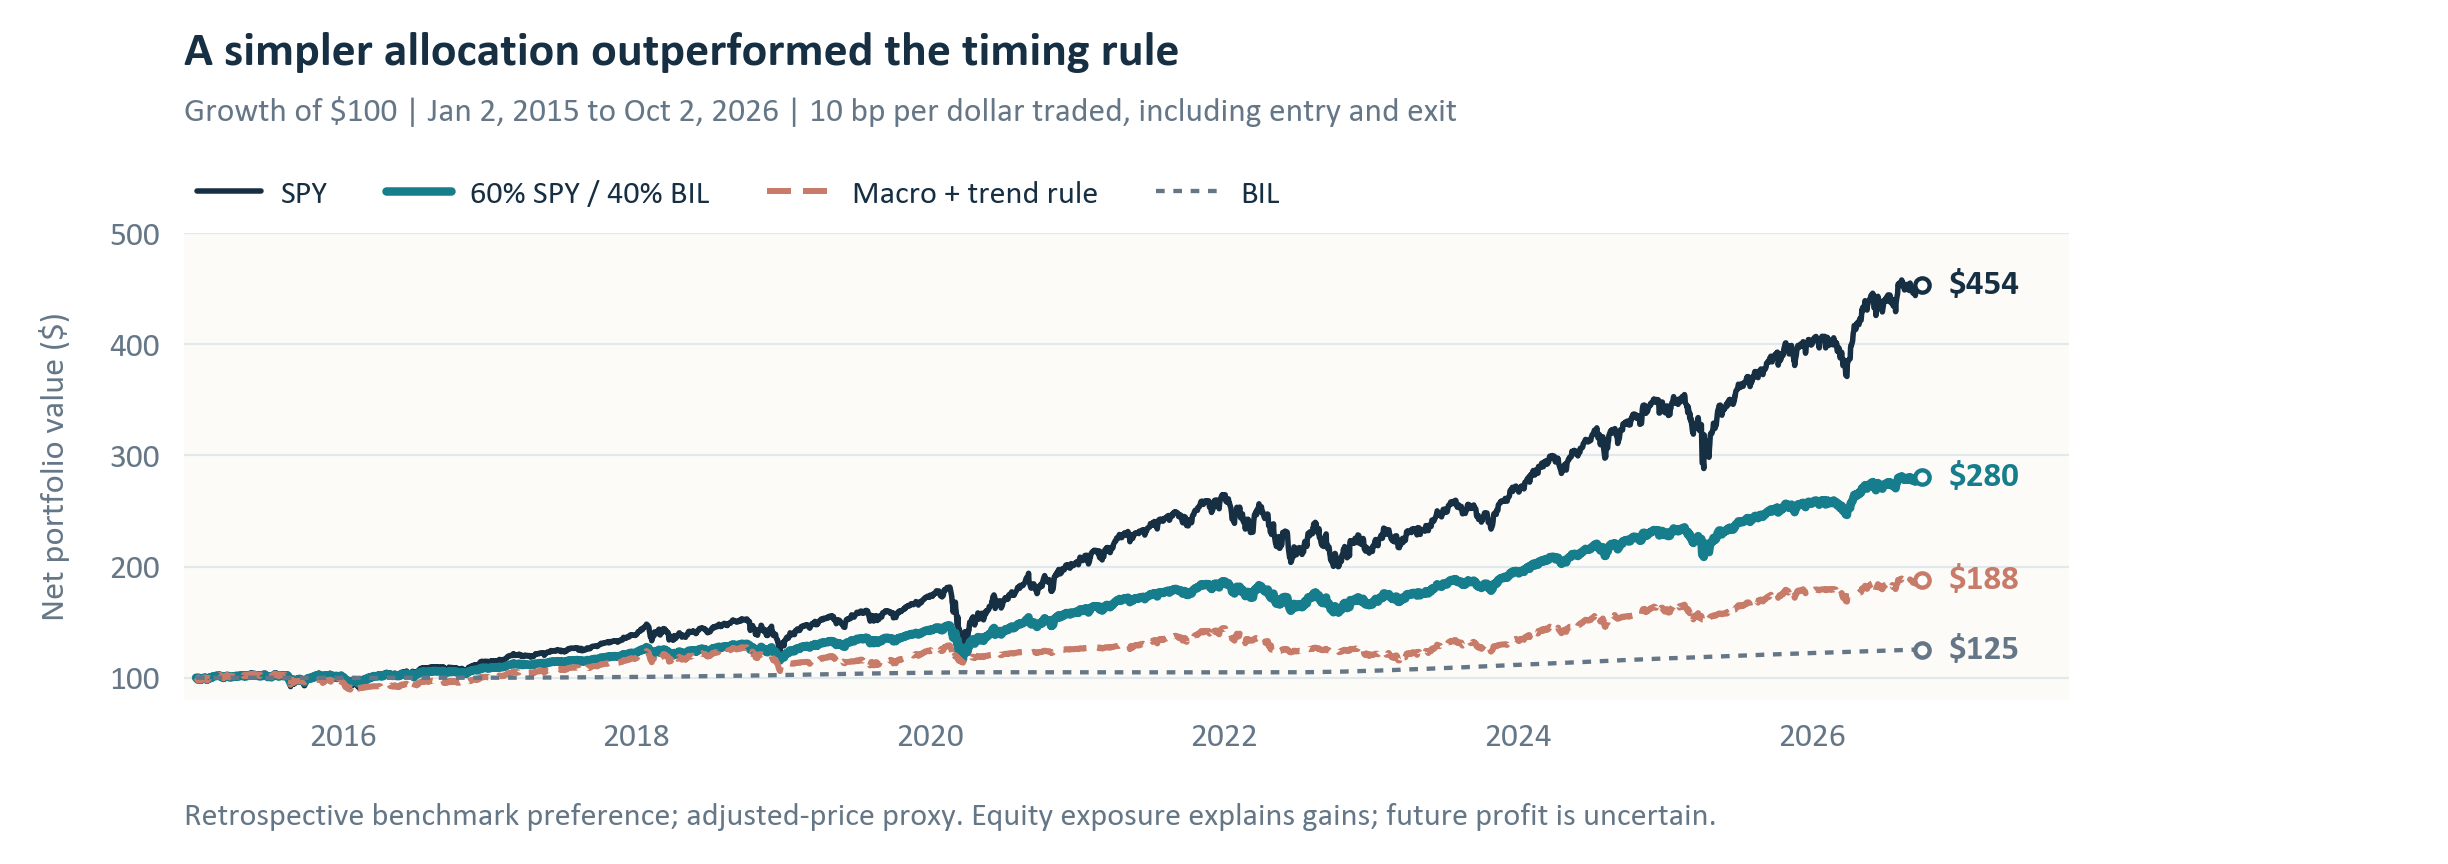

In [11]:
display(Image(filename=str(ROOT / 'outputs/investment_strategy.png')))

## Three aggressive strategies that use only earlier news wording

A strategy is a rule for choosing what to buy. These three ideas use the same national-minus-local negative-wording score. None uses economic releases, survey answers or stock-price trends to choose funds. UPRO aims for three times the S&P 500's DAILY move; SPXU aims for three times the opposite DAILY move. These are risky daily targets, not promises for an entire month. Their actual historical fund prices are used. The fixed rules, current-month exclusion, costs and all benchmark results appear below. A losing idea is retained. These historical simulations do not establish verified bias or a future investment advantage.

In [12]:
bias = json.loads((ROOT / 'outputs/tables/bias_trading_summary.json').read_text())
bias_metrics = pd.read_csv(ROOT / 'outputs/tables/bias_trading_metrics.csv')
print('All rules and all benchmarks, on exactly the same dates:')
display(bias_metrics.loc[bias_metrics.cost_bps.eq(10)])
print('Cost sensitivity for the three ideas:')
display(bias_metrics.loc[bias_metrics['sample'].eq('full') & bias_metrics.model.isin(bias['rule_names']), ['model','cost_bps','net_cagr','net_total_return','max_drawdown','terminal_value_10000']])
print('How often each rule chose each fund:')
display(pd.DataFrame(bias['rule_fund_counts']).fillna(0).astype(int))
print('Three historical return comparisons, with Holm correction (not alpha tests):')
display(pd.DataFrame(bias['tests_vs_spy']))
print('Signal inputs only:', bias['signal_inputs_only'])
print('Limitations:', *bias['limitations'], sep='\n- ')

All rules and all benchmarks, on exactly the same dates:


,sample,model,label,cost_bps,allocation_periods,start,end,...,terminal_value_10000,annual_gross_turnover,orders,average_weight_UPRO,average_weight_SPXU,average_weight_SPY,average_weight_BIL
9,full,Fade_gap,Fade the gap,10,68,2021-02-02,2026-10-02,...,14351.9561,13.7628,78,0.5608,0.4238,0.0000,0.0155
10,full,Follow_gap,Follow the gap,10,68,2021-02-02,2026-10-02,...,1852.2750,13.7628,78,0.4238,0.5608,0.0000,0.0155
11,full,Wait_turn,Wait for a turn,10,68,2021-02-02,2026-10-02,...,13867.5287,8.1166,46,0.1202,0.0738,0.0000,0.8060
12,full,SPY_hold,S&P 500 fund (SPY),10,68,2021-02-02,2026-10-02,...,21734.1776,0.3531,2,0.0000,0.0000,1.0000,0.0000
13,full,BIL_hold,Treasury-bill fund (BIL),10,68,2021-02-02,2026-10-02,...,11941.2691,0.3531,2,0.0000,0.0000,0.0000,1.0000
14,full,UPRO_hold,Always 3x up (UPRO),10,68,2021-02-02,2026-10-02,...,38771.7459,0.3531,2,1.0000,0.0000,0.0000,0.0000
15,full,SPXU_hold,Always 3x down (SPXU),10,68,2021-02-02,2026-10-02,...,772.9254,0.3531,2,0.0000,1.0000,0.0000,0.0000
16,full,Two_sided_50_50,Half UPRO / half SPXU,10,68,2021-02-02,2026-10-02,...,9202.0921,1.5814,138,0.5046,0.4954,0.0000,0.0000
17,full,Static_60_40,60% SPY / 40% BIL,10,68,2021-02-02,2026-10-02,...,17327.5715,0.5496,138,0.0000,0.0000,0.6006,0.3994
36,2021_2023,Fade_gap,Fade the gap,10,35,2021-02-02,2024-01-02,...,12968.5826,12.3461,36,0.6576,0.3424,0.0000,0.0000


Cost sensitivity for the three ideas:


,model,cost_bps,net_cagr,net_total_return,max_drawdown,terminal_value_10000
0,Fade_gap,0,0.0807,0.5516,-0.6352,15516.2254
1,Follow_gap,0,-0.2473,-0.7997,-0.8847,2002.5365
2,Wait_turn,0,0.0681,0.4520,-0.3416,14520.3347
9,Fade_gap,10,0.0659,0.4352,-0.6373,14351.9561
10,Follow_gap,10,-0.2576,-0.8148,-0.8907,1852.2750
11,Wait_turn,10,0.0594,0.3868,-0.3443,13867.5287
18,Fade_gap,25,0.0441,0.2767,-0.6406,12767.2828
19,Follow_gap,25,-0.2727,-0.8352,-0.8992,1647.7558
20,Wait_turn,25,0.0466,0.2943,-0.3482,12942.9316


How often each rule chose each fund:


,Fade_gap,Follow_gap,Wait_turn
UPRO,38,29,8
SPXU,29,38,5
BIL,1,1,55


Three historical return comparisons, with Holm correction (not alpha tests):


,model,annualized_daily_intercept,lower_95,upper_95,pvalue,n,market_beta,method,holm_pvalue
0,Fade_gap,0.0319,-0.3510,0.4149,0.8702,1424,None,OLS HAC(21); annualized arithmetic daily intercept,0.8702
1,Follow_gap,-0.3311,-0.7565,0.0942,0.1270,1424,None,OLS HAC(21); annualized arithmetic daily intercept,0.3811
2,Wait_turn,-0.0739,-0.2363,0.0885,0.3727,1424,None,OLS HAC(21); annualized arithmetic daily intercept,0.7455


Signal inputs only: ['Reuters negative-headline share', 'NPR negative-headline share', 'Colorado Sun negative-headline share', 'their previous calendar months']
Limitations:
- Relative negative wording is an unvalidated proxy, not verified factual or ideological bias
- Retrospective titles, model availability and revised adjusted prices prevent a historical implementability claim
- Rules were designed after earlier project/market findings; no untouched future test exists
- Very aggressive products can lose nearly all capital; daily reset compounds and monthly holdings differ from 3x monthly market return
- Assumed costs omit taxes, nonlinear impact and investor-specific commissions


## The question and the main findings

People can hear that the economy is growing and still worry about paying their bills. This project asks why. The University of Michigan’s consumer sentiment index is a survey score about people’s finances, business conditions and buying plans. Higher means more optimism. A score of 60 does not mean 60% of people are happy; this index is not a percentage or a scale capped at 100.

We compare three explanations: household pressures missed by national statistics; the stories people see and how those stories are worded; and problems with the data or forecasting model. Artificial intelligence (AI) software labels headline wording. A negative headline can accurately describe bad news, so negative does not automatically mean biased.

The first forecasting model, called M1, uses jobs, prices and national output. For the latest completed month, the actual survey score was 48.1 and M1 predicted 70.7. The gap is actual minus predicted: -22.6 points. For example, an actual score of 60 minus a prediction of 70 gives a gap of −10. A gap is a model’s mistake, not proof that people are irrational.

Across the same 44 test months, adding headline tone lowers the forecast-error score by 0.01 survey points. When the model also knows last month’s survey, headlines lower the score by 0.04 points. Statistical uncertainty does not establish a reliable gain. The provider comparison asks whether outlets describe the same releases differently; it cannot measure dishonesty or effects on readers.

In [13]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[0][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,What we use,What it can tell us
0,Economy,"Monthly history from 2010; earlier published versions of the jobs,..."
1,Headlines,"3,787 titles in 82 months; national news, local news and Hacker News"
2,Study date,"Economic information frozen October 13, 2026; October survey/news ..."
3,Accuracy checks,AI checks completed; the required two independent human reviewers ...
4,How to read this report,Part A: empirical study; Part B: evidence-led manifesto; appendice...


**Main conclusion.** This sample does not establish that media bias explains the sentiment gap. Household conditions, survey methods, persistence and measurement remain plausible explanations. Part B asks how readers can strengthen independent judgment; its broader arguments are distinguished from the results of Part A. The human-annotation requirement remains unmet.

## Check what was known at the time

A number’s date can mean the month it describes, not the day people first learned it. Using a later release in an earlier prediction would be like answering a quiz after seeing the answers. The spreadsheet has four separate date/value pairs, so they must be joined by the periods they describe.

Official jobs data come from the Bureau of Labor Statistics (BLS). Prices and output come from the Bureau of Economic Analysis (BEA). Gross domestic product (GDP) means the country’s total economic output. The Personal Consumption Expenditures (PCE) price index tracks consumer prices. The required headline index includes food and energy; the core index leaves them out.

In [14]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[1][1][2]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Spreadsheet issue,What the official records show
0,October survey: 46.3,"A first estimate was released October 9. Keep it for monitoring, s..."
1,July–September GDP: 3.7,"The first official release is October 29, after our cutoff. Do not..."
2,August inflation: 3.00759,All 584 spreadsheet values match core inflation. Required headline...
3,October 2025 unemployment missing,BLS did not collect the household survey during the shutdown. Do n...
4,GDP later revised,September 30 updates cannot enter predictions made before that date.


We use the Federal Reserve’s historical data archive, ALFRED, to recover earlier published versions of the economic numbers. The saved files record request addresses, download times and digital fingerprints that reveal file changes. This makes the economic inputs checkable.

There is still a limit: the downloaded Michigan history contains today’s final survey values, not every version originally published. Old headlines may also have been edited or removed. The notebook saves summary results, while detailed data stay local under the project's established no-data-sharing policy. A fresh download may not recover exactly the same sample.

## Build a fair forecast

A forecast is a prediction made before its answer is published. For each target month, we use the economic data available by the end of its first calendar day. We cannot recover every release’s exact hour, so we allow the whole first day. GDP is published quarterly, every three months: keep the latest known quarter until a new release arrives, rather than invent monthly GDP figures.

In [15]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[2][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Input,Meaning and calculation
0,"Unemployment, official U-3 rate",Share of the labor force without a job and actively seeking work. ...
1,Headline PCE inflation,Percentage price change over twelve months: 100 × (current index /...
2,Real GDP growth,Output growth after allowing for price changes. Main measure: 100 ...
3,Alternative GDP measure,Compare output with the same quarter a year earlier. This is diffe...
4,Household pressures,Add three years of accumulated price increases and growth in after...


The overall survey, its Current Economic Conditions score and its Consumer Expectations score are analyzed separately. Current Economic Conditions describes today; Consumer Expectations asks about the future. These questions cover everyday finances and buying decisions, so unemployment, inflation and GDP cannot be expected to explain everything.

Each model learns from months before its prediction month. A simple comparison repeats last month’s survey score. News enters with a one-month delay, and October’s incomplete news cannot be used to make an October 1 prediction. Some survey interviews began in the previous month, so the prediction is before the published score but not necessarily before every interview.

Each record keeps the period its number describes and the historical data version used. Missing calendar months cannot be skipped when calculating a twelve-month change. The model adds weighted inputs. Ordinary least squares chooses weights to make earlier squared mistakes as small as possible. The notebook includes the formulas, release records and checks; revised survey histories remain a limitation.

**Technical specification.** At origin t, expanding ordinary least squares (OLS) fits sentiment on a constant, the latest released U-3, headline PCE inflation and quarterly real-GDP growth. OLS chooses coefficients to minimize squared past errors. Rebuild at each origin with at least 60 earlier monthly rows for the long panel. The gap g(t) = observed sentiment(t) - predicted sentiment(t) is an out-of-sample residual, not an estimated psychological bias. All three survey outcomes use their own fitted model.

## How wrong were the forecasts?

M1 learns from at least 60 earlier months of unemployment, headline inflation and GDP. We test it on later months, then move forward and repeat. This is an out-of-sample test: each answer belongs to a later month than the months used for learning.

Root mean squared error (RMSE) is a forecast-error score, measured here in survey points. Square each mistake, average the squares, then take the square root. Errors of 3 and 4 points give square root of ((9 + 16) / 2) = 3.54. Bigger errors receive extra weight; lower is better.

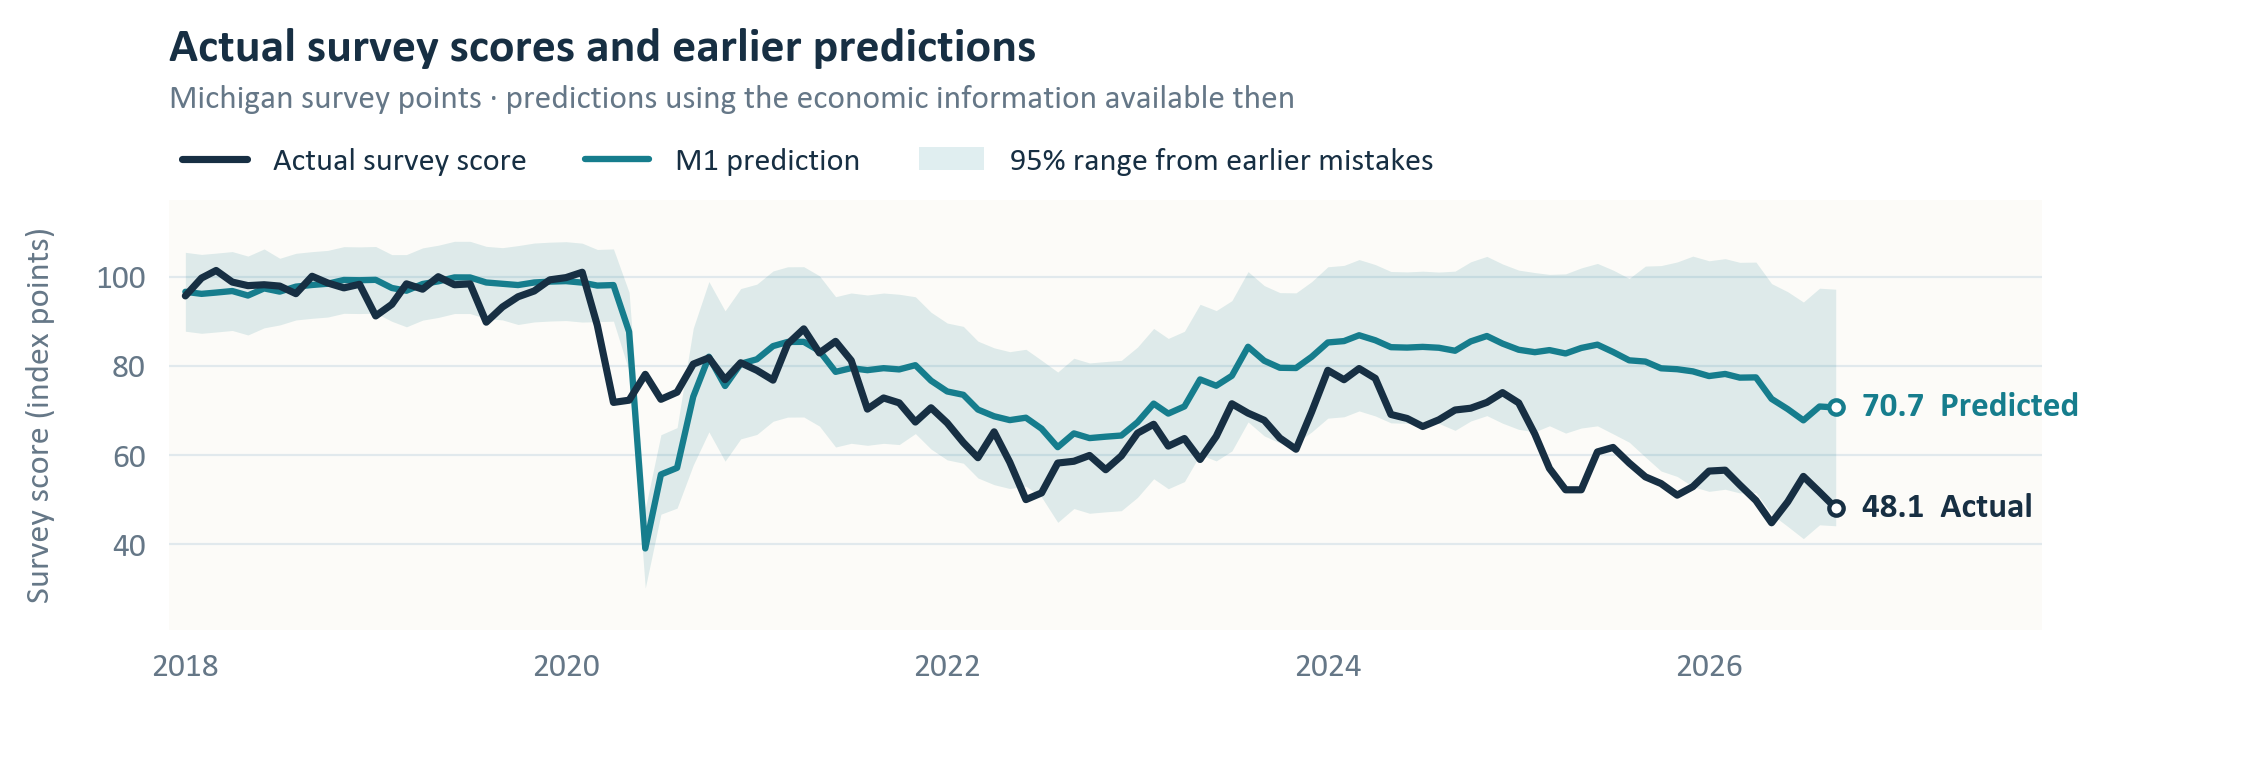

In [16]:
display(Image(filename=str(ROOT / 'outputs' / 'economic_forecast.png')))

The dark line is the actual survey score; the other line is M1’s earlier prediction. The shaded prediction interval is a plausible range based on earlier errors, not a guarantee. An absent band means too little earlier error history.

Across 141 test months, M1’s error score is 12.35 points. Simply repeating last month’s survey scores 4.26, much better. Separate models for current conditions and expectations score 16.50 and 10.44. The three economic inputs alone therefore leave important information out.

A range aimed at 95% coverage should contain the answer about 95 times in 100 comparable tests. M1’s formula-based range covers only 72.3% of outcomes. A range built from earlier errors covers 78.4% of 116 usable tests. September’s 48.1 is below the first range, 50.23–91.10, but inside the second, 44.13–97.21. How unusual the gap looks depends on the uncertainty calculation.

Mistakes in nearby months are related, and relationships changed around the pandemic and inflation surge. The notebook checks shorter learning windows, seasons, different GDP definitions and survey methods. It also lets a model learn from the previous survey rather than assuming three national statistics are enough.

## Other reasons people may feel worse

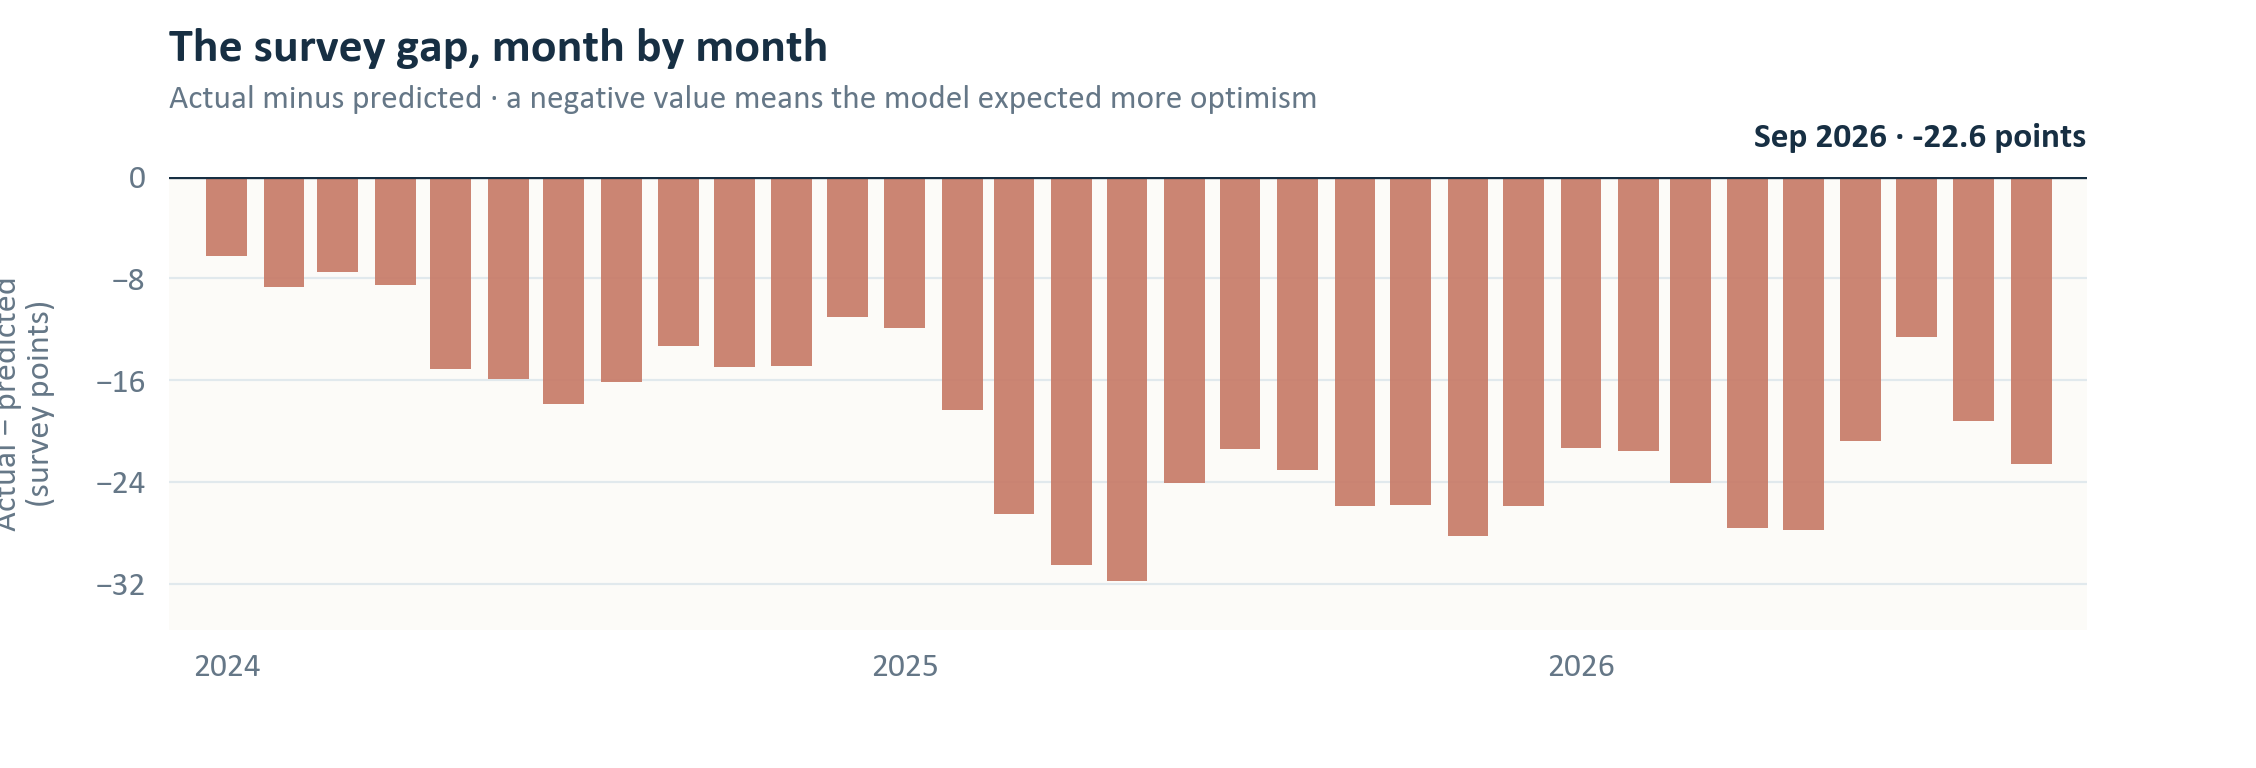

In [17]:
display(Image(filename=str(ROOT / 'outputs' / 'recent_gap.png')))

Each bar is actual sentiment minus M1’s earlier prediction. A bar below zero means M1 expected more optimism. It is not a percentage of irrational people or an estimated media effect.

Falling inflation does not mean prices returned to their old level. Suppose a basket rises from $100 to $110, then to $112.20. Inflation slows from 10% to 2%, but the basket still costs 12.2% more than before. We therefore add accumulated price increases and inflation-adjusted household income. Housing costs, debt, inequality and job insecurity can still be missing.

Adding these household measures lowers the long-period error score from 12.35 to 11.01 across 141 months. But in the 44 months with headline data, they score 12.01 versus 11.85 for M1. The benefit changes with the period. This does not identify one household pressure as the cause of the gap.

How the survey is collected can also matter. Michigan moved from phone to web, with web shares of 25%, 50%, 75% and 100% from April through July 2024. Allowing a gradual change over those months reduces September’s gap to −3.99; a model that also knows earlier sentiment gives −4.64 instead of M1’s −22.57. Many things changed at once, so this does not prove the survey switch caused the gap. Michigan’s revised July 2026 report still finds low sentiment when comparing the same collection methods.

Michigan reports differences by political affiliation, income and stock ownership. Its October description highlights lower-income households and smaller portfolios. These published summaries provide context, not individual records in our dataset. We cannot estimate what a particular political group read, believed or experienced.

One month’s sentiment is strongly related to the next: their correlation is 0.959 on a scale where +1 means a perfect positive relationship. That makes last month’s survey a demanding comparison. Two statistical checks warn that long-run relationships may shift; their full results are in the notebook. A separate test predicts monthly changes instead of levels. Adding headlines changes its error score from 4.2227 to 4.2234, with no reliable improvement.

## What the headline sample represents

The sample runs from January 2020 through October 12, 2026: 81 complete months and an incomplete October. National sources are the Associated Press, Reuters and National Public Radio (NPR). Local sources are Gothamist, Texas Tribune and Colorado Sun. Hacker News supplies user-posted story titles. The same search topics cover the economy, inflation, jobs, wages, housing and living costs; searches do not ask only for bad news.

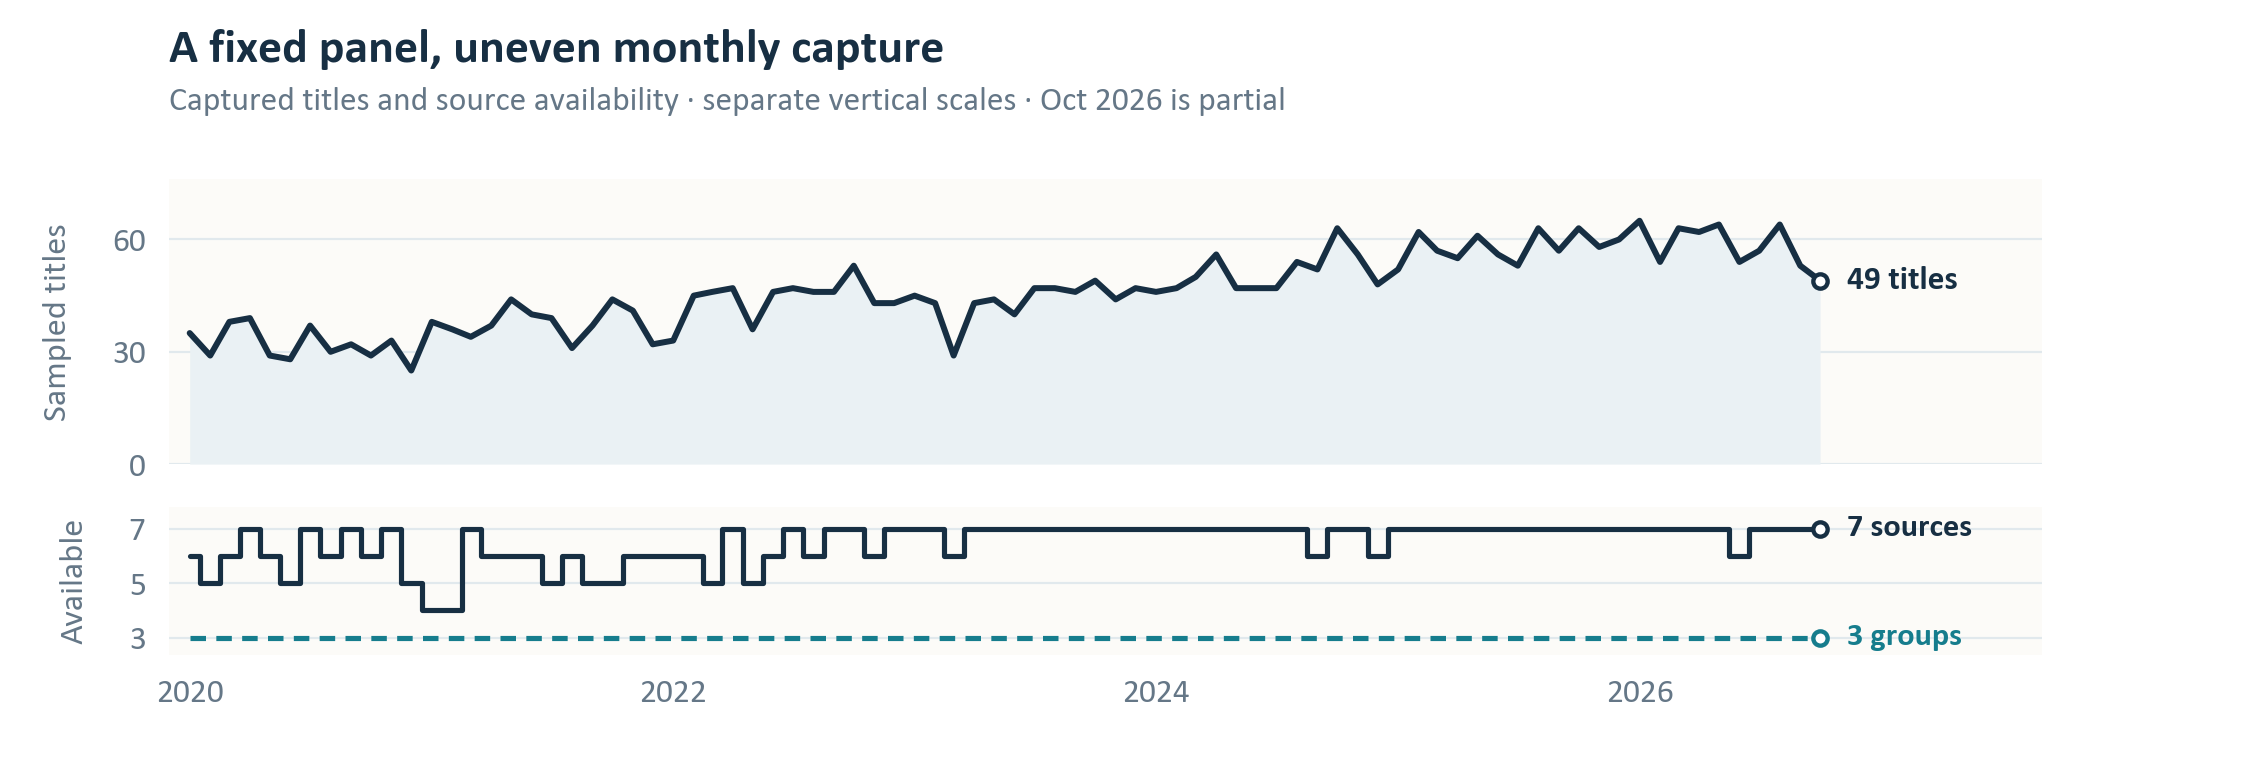

In [18]:
display(Image(filename=str(ROOT / 'outputs' / 'media_coverage.png')))

Top: number of captured titles. Bottom: number of available sources and source groups, using a different vertical scale. A missing source does not mean it published no economic news.

We measure titles, not complete articles, comments or what survey respondents actually saw. A repeatable computer rule selects at most twelve titles per source per month. First average titles within a source, then sources within each national/local/social group, then give each available group equal weight. A busy publisher therefore cannot dominate just by supplying more headlines.

We remove exact duplicates, repeated records, obvious promotions, wrong dates and clearly foreign-only titles. Similar rewritten stories, unknown geography and possible automated posts cannot all be resolved. Hacker News is a selected technology community, not a representative sample of American adults. A vote count seen at download time cannot tell us who saw the original post years earlier.

Search feeds rank and limit their results. Headlines can change or disappear, and missing sources can change the measured tone. Content supply means what is published; engagement means actions such as voting; exposure means what a person actually encounters. These are different. The dashboard shows source counts so readers can check whether a change in tone also reflects a change in the sample.

## Turn wording into checkable measurements

In [19]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[6][1][0]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,What we measure,Plain meaning and boundary
0,Tone,How positive or negative the wording sounds. The model score is po...
1,Topic attention (salience),"How much of the captured coverage mentions jobs, layoffs, prices, ..."
2,Framing,Which aspect is emphasized: high prices versus slowing inflation; ...
3,Fact checking (calibration),"Compare a numerical claim with the right official measure, period ..."
4,Political credit/blame,Who is mentioned and who appears to receive credit or blame. Criti...


The coding guide was written before scoring; later changes to headline eligibility are documented. A fixed Cardiff language model reads words in context. We compare it with VADER, a word-list sentiment method. The model was not trained on Michigan survey outcomes. Word-match rules for topics, emotion, framing and blame remain rough indicators awaiting human checks.

Bad facts and emotional wording are different: "unemployment rose" can be an accurate, calmly worded report. A model released in 2022 also could not have been used in 2020. Our earlier text scores use that later tool and headlines retrieved now, so they are historical reconstructions, not proof of what a working system could have known then.

A fair comparison needs a reference. The provider comparison examines providers covering the same official reports. It cannot make every truthful detail identical. Testing equal good/bad economic surprises would also need the forecasts people expected beforehand and a fuller record of what was published. Eight selected unemployment-title percentages match official releases, but incomplete definitions, periods and release times prevent a full accuracy judgment.

In [20]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[6][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Measurement,January–September 2026: average monthly result
0,Tone,Score -0.199; 30.2% negative; 6.5% flagged emotional words
1,Topic attention,22.7% housing; 5.7% wages; 1.9% layoffs; 1.6% hiring
2,Framing,24.1% price level versus 18.2% inflation rate; 7.4% household vers...
3,Political credit/blame,15.5% political mentions; 0.4% credit and 1.0% blame word matches


These results use 9 complete months and 536 titles. Each month and source group counts equally; topics can overlap. The 30.2% negative measure describes weighted headlines, not unhappy people. Negativity bias means giving bad news extra weight; availability bias means judging by what comes easily to mind; confirmation bias means favoring an existing belief; anchoring means relying on an earlier reference such as an old price. Titles alone cannot show these processes inside readers’ minds.

Changing political names switched 5/100 labels (average size of score change 0.076); adding a Gothamist name tag switched 12/100 labels (average size of score change 0.102), and a Reuters prefix 12/100 labels (average size of score change 0.083). The scoring therefore hides source names. A changed name can also change meaning, so these checks alone do not prove political unfairness.

## Calibration / Check a fact before judging its framing

A negative sentence can be true, and a reassuring sentence can omit a relevant fact. We therefore keep tone and factual calibration separate. Here is a small, purposive check of unemployment percentages, using the archived BLS release for the same publication day. It checks a number at the precision in a title, not the entire story.

In [21]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[7][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Captured title source / day,Period in BLS release,Title percentage,Official U-3
0,Associated Press / 2020-05-08,2020-04,14.7%,14.7%
1,Hacker News / 2020-06-05,2020-05,13.3%,13.3%
2,Reuters / 2022-04-01,2022-03,3.6%,3.6%
3,Reuters / 2024-08-02,2024-07,4.3%,4.3%


All 8 selected percentages numerically match. Only 2 titles name a month; none is fully verified for definition, period and intraday release vintage. Feed timestamps can precede the official release even when our conservative availability date is later. The correct description is numeric alignment, not an 8/8 factual-accuracy estimate, and not an estimated error rate for the full sample.

Official references for these examples: [April 2020 release](https://www.bls.gov/news.release/archives/empsit_05082020.htm), [May 2020 release](https://www.bls.gov/news.release/archives/empsit_06052020.htm), [March 2022 release](https://www.bls.gov/news.release/archives/empsit_04012022.htm), [July 2024 release](https://www.bls.gov/news.release/archives/empsit_08022024.htm). The local ledger preserves all eight title excerpts, definitions and unresolved checks.

In [22]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[7][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Corpus group,Titles; whole captured sample,Scope
0,National,"2,071","AP, NPR and Reuters; no measured respondent exposure."
1,Local,741,"Gothamist, Texas Tribune and Colorado Sun; geography and topics di..."
2,Social,975,"Hacker News titles; selected users, votes at download time, unreso..."


The sampling cap is twelve titles per source/month after filtering; ranked search can already omit material before that cap. Missing coverage is visible in the dashboard. Source balancing reduces volume dominance but does not make the sample representative. We use no individual Michigan records, identify no social users in outputs and estimate no demographic effects from unavailable data.

Public access does not grant blanket permission to republish news. The project stores the title-level analytical inputs locally and publishes code and aggregates. Model and dataset attributions, access boundaries, privacy treatment and the separate external benchmark license are documented in docs/DATA_ACCESS_AND_ETHICS.md.

## Validation / Human requirements and an external stress test

**The required project annotation is incomplete.** The assignment asks two independent people to label at least 300 stratified items. Completed human labels are unavailable. The blinded 300-item worksheets, evidence guide, agreement calculation and adjudication workflow are ready. Separate AI reviews are identified as AI throughout; they do not satisfy that requirement. No target-corpus human accuracy or agreement is invented.

To test the sentiment model against existing human judgments, we added a separate Financial PhraseBank benchmark. Its authors used multiple annotators to label company-news sentences from an investor perspective. Before scoring, we fixed 300 unique unanimous-consensus sentences, 100 per class, selected by deterministic hash. No thresholds were tuned on these results. This is an external transfer test, not a substitute for human labels on our economic titles.

In [23]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[8][1][2]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,External method; n = 300,Accuracy,95% Wilson range,Macro-F1
0,Context model,53.7%,48.0-59.2%,0.513
1,VADER word list,51.0%,45.4-56.6%,0.478


In [24]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[8][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Human reference class,n,Context recall,VADER recall
0,Negative,100,0.35,0.19
1,Neutral,100,0.97,0.59
2,Positive,100,0.29,0.75


The context model calls 232 of 300 items neutral. Its apparently high negative/positive precision coexists with poor recall: it misses many human-labeled examples. The small accuracy difference does not establish a clear advantage over VADER. Company/investor labels differ from wording valence, the balanced unanimous sample changes prevalence and difficulty, and model-training overlap is unknown. These are serious limits to transfer, not evidence that the economic-title accuracy equals 53.7%.

Wilson ranges describe binomial agreement uncertainty conditional on this selected sample; they omit unknown sentence/source dependence and domain shift. Full class scores and confusion matrices are in the notebook. The next page returns to the project's AI-only diagnostic, with its own explicitly different reference population.

Primary source: [Malo et al., Good Debt or Bad Debt (2014; author preprint)](https://arxiv.org/abs/1307.5336v2); [author distribution](https://huggingface.co/datasets/takala/financial_phrasebank). Dataset license: CC-BY-NC-SA-3.0. The frozen sampling protocol and license files are recorded; sentence-level data remain local.

## Validation results / Keep the reference population visible

These tables use only the final-eligible part of the AI review. Of the original 300 titles, 277 survive final relevance checks; 23 remain archived as excluded. AI A has 231 positive/neutral/negative reference answers and 46 mixed/uncertain answers; AI B has 232 and 45. The three-class comparisons exclude the latter rather than relabeling them. These are development diagnostics against AI judgments, not estimates of human accuracy.

In [25]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[9][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,AI reference,Method,n,Agreement,Macro-F1
0,AI a,Context model,231,73.2%,0.707
1,AI a,VADER word list,231,62.3%,0.590
2,AI b,Context model,232,71.1%,0.683
3,AI b,VADER word list,232,63.4%,0.602


F1 balances precision (how often a predicted class matches the reference) and recall (how many reference items in that class were found). Macro-F1 averages the three class scores equally. Below, both tables use AI A; the notebook shows AI B, precision, recall, confusion matrices and the original cohort as well.

In [26]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[9][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Reference class,n,Context F1,VADER F1
0,Negative,114,0.818,0.743
1,Neutral,39,0.534,0.389
2,Positive,78,0.769,0.639


In [27]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[9][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,"Source, final-eligible",n,Context macro-F1,VADER macro-F1
0,Associated Press,31,0.659,0.630
1,Colorado Sun,37,0.782,0.572
2,Gothamist,31,0.764,0.459
3,Hacker News,36,0.735,0.615
4,NPR,35,0.735,0.582
5,Reuters,30,0.637,0.726
6,Texas Tribune,31,0.556,0.451


Neutral cases are harder than the overall average suggests, and VADER performs better for the Reuters subset against AI A. Small cells, correlated machine errors and review-driven development limit interpretation. Source-specific performance is not evidence of publisher dishonesty. No CNBC or Fox titles occur in this original validation pool.

## Do headlines improve the prediction?

We compare the same test months. M1 uses the economy only. M2 adds the previous month’s headline tone. M3 also adds household income and accumulated prices. These comparisons learn from February 2020 onward, using at least 36 earlier months. They differ from the longer-history M1 chart on page 4. A household-only addition and models using last month’s survey help show what actually adds information.

**Model comparison.** All three core models use expanding OLS, a constant and identical 44 test months. M2 adds one-month-lagged source-balanced tone; M3 adds three-year cumulative prices and real disposable-income growth. M1 + household controls isolates what media adds beyond those controls. Lagged-survey models test persistence. Predictive value means lower later forecast loss; none of these coefficients identifies a causal news effect.

In the table, Months is the number of tests. RMSE is the error score defined on page 4. Mean absolute error (MAE) is the average size of the mistakes, ignoring their signs. Coverage is the share of answers inside a range intended to cover 95%. Lower errors and coverage near 95% are better; a range can also be too wide to be useful.

In [28]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[10][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Forecast rule,Months,RMSE,MAE,Range coverage
0,Learn from last month’s survey,44,4.32,3.57,100.0%
1,Last survey + economy,44,4.66,3.91,95.5%
2,Last survey + economy + headlines,44,4.62,3.93,97.7%
3,Economy + household pressures,44,12.01,9.77,77.3%
4,M1: economy only,44,11.85,10.01,79.5%
5,M2: economy + headlines,44,11.85,10.07,81.8%
6,M3: add household pressures,44,11.95,9.82,77.3%
7,Repeat last month’s survey,44,4.27,3.54,—


Test months: 2023-02-01 to 2026-09-01. Across the same 44 test months, adding headline tone lowers the forecast-error score by 0.01 survey points. When the model also knows last month’s survey, headlines lower the score by 0.04 points.

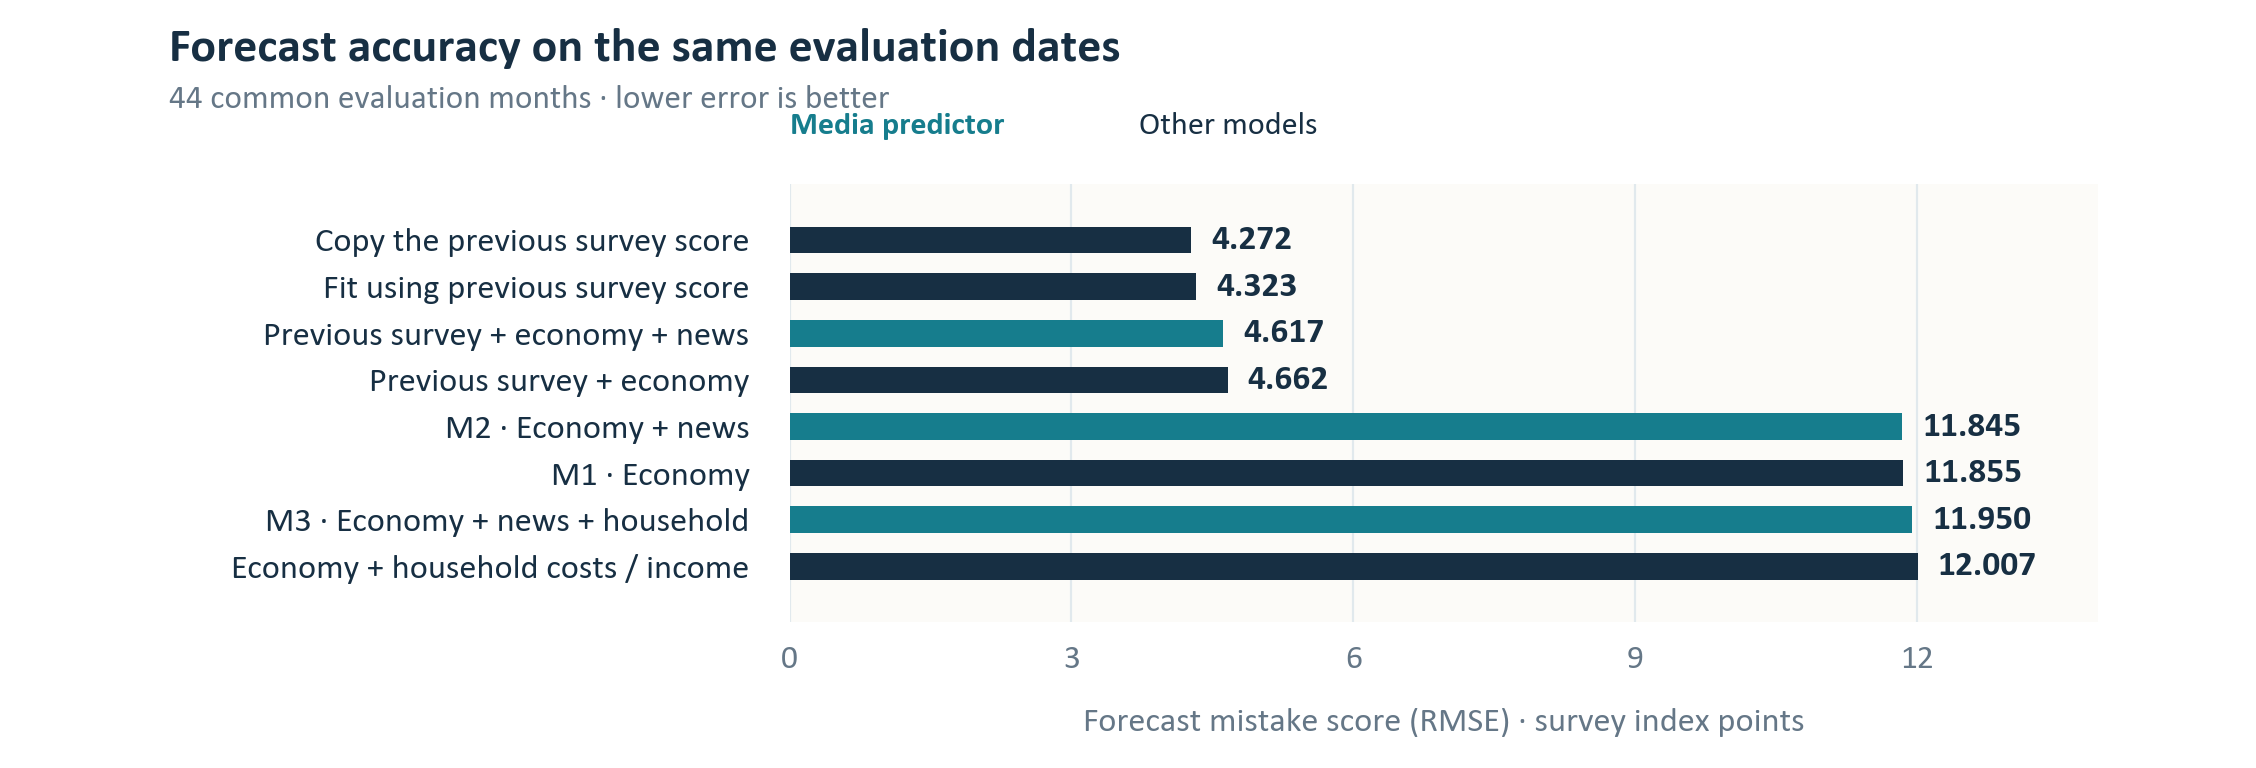

In [29]:
display(Image(filename=str(ROOT / 'outputs' / 'model_accuracy.png')))

Error scores for identical test months. Lower bars mean smaller mistakes. The very small gain from headlines does not show that headlines caused survey sentiment to fall.

## Uncertainty / Does the apparent gain survive scrutiny?

A tiny change in the average error can occur by chance, especially when neighboring months share shocks. We compare paired squared forecast errors from exactly the same 44 months. Units are mean squared survey points, not changes in RMSE. A negative difference favors headlines. The uncertainty calculation allows errors up to three months apart to be related: heteroskedasticity and autocorrelation consistent (HAC), bandwidth 3. Intervals are pointwise; the BH correction applies to q-values only. Neither corrects omitted variables or missing exposure data.

In [30]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[11][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Comparison: added minus baseline,Mean loss difference,95% HAC interval,BH q
0,M2 - M1,-0.225,"[-7.09, 6.64]",0.949
1,M3 - economy + household,-1.362,"[-11.84, 9.11]",0.949
2,Lagged survey + media - without media,-0.414,"[-2.28, 1.45]",0.949


Benjamini-Hochberg (BH) adjusts this declared family of three media-addition comparisons for multiple testing. All q-values are 0.949; none supports a reliable gain at a 5% threshold. A q-value is not the probability that the null hypothesis is true. Small samples, nested forecast models and specification choices make these exploratory uncertainty estimates rather than decisive evidence of zero effect.

In [31]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[11][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Change one assumption,Earlier / reference RMSE,Changed RMSE,Meaning
0,Use VADER word list,11.855,12.003,No gain from the simpler wording measure.
1,Exclude social posts,11.855,11.929,The conclusion depends partly on source definition.
2,Train only after 2022; n = 9,4.527,4.576,Reduces early-model lookahead; very short test.
3,Predict monthly changes,4.2227,4.2234,Adding tone still gives no meaningful gain.


M2 is rebuilt 44 times. A one-point increase in earlier tone changes its prediction by -1.57 to 17.54 survey points, depending on the learning period; the link is positive 37 times. Changing signs warn that the link is unstable. After allowing for three comparisons, statistical checks do not establish a reliable improvement. The notebook checks different time lags, sources and wording rules, and allows errors in nearby months to be related. Such calculations cannot fix a poorly specified model.

In a separate fitted association over 80 historical months, a +0.1 shift in tone is associated with +1.66 survey points in M2, with a HAC(3) 95% interval from -1.14 to +4.46. This full-history coefficient is not an out-of-sample gain or a causal effect. Its wide interval and unstable rolling coefficients argue against treating the point estimate as a dependable response.

Prediction intervals ask where one future survey value might fall. For long-history M1, the empirical interval uses only errors before each origin, with at least 24 earlier errors. It never uses that month's answer to calibrate its own range. Coverage is 78.4% over 116 calibrated tests, a different sample from the 44-month comparison above. Nominal 95% is not a guaranteed probability.

The notebook also reports seasonality, rolling windows, alternative GDP growth, publication-lag and source-weight checks, all with their actual evaluation samples. These checks are exploratory and were not used to search for a favorable headline model. Full coefficients, HAC intervals, diagnostics and the experimental power calculation appear in docs/STATISTICAL_EVIDENCE.md and docs/CAUSAL_POWER_PLAN.md.

## What would show cause and effect?

Two things moving together does not show which caused which. Job losses may worsen both news and sentiment. Worried readers may seek bad news, and publishers may respond to that demand. Political identity can affect both source choice and survey answers. Monthly national averages cannot separate these paths.

The assignment permits observational analysis with a detailed causal proposal. Our proposed study has three equally accurate summaries of one release: a balanced fact sheet, an emphasis on cumulative prices, and an emphasis on annual inflation. Keep numbers, source, length and difficulty identical. The primary comparison is price-level minus inflation-rate framing on a next-day sentiment-related composite, adjusting for its baseline and randomization blocks. No participants were recruited.

For a prospective effect of 0.25 standard deviations, a two-sided 5% test and 80% power, the finite-sample calculation requires 253 observed outcomes per compared arm. Plan 317 randomized per arm to allow 20% missing outcomes: 951 across three arms. These are planning assumptions, not results or an achieved precision guarantee. Analyze original assignment (intention to treat), report attrition, and apply Holm correction to prespecified secondary contrasts. The balanced arm and immediate/one-week checks assess interpretation and persistence; research approval and funding are prerequisites.

In [32]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[12][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Evidence against a media-bias explanation,What it would mean
0,Headlines add no reliable forecasting gain,The text may add little beyond economic conditions and last month’...
1,Household or survey-method checks shrink the gap,Everyday costs or measurement differences may explain it.
2,Negative headlines accurately describe bad outcomes,Reporting bad news does not establish distorted coverage.
3,Provider differences disappear after expected-news checks,Different surprises may explain different wording.
4,A large enough framing experiment finds no effect,The tested wording may not change beliefs through the proposed route.


Even a convincing experiment with volunteers would not establish an effect on the national Michigan score. We would also need to know what the wider population saw, recruit or reweight a representative sample, compare the same outcomes, and justify applying the result to other people. The detailed plan, including these assumptions, is in docs/causal_design.md.

## Provider comparison / The same releases, different wording

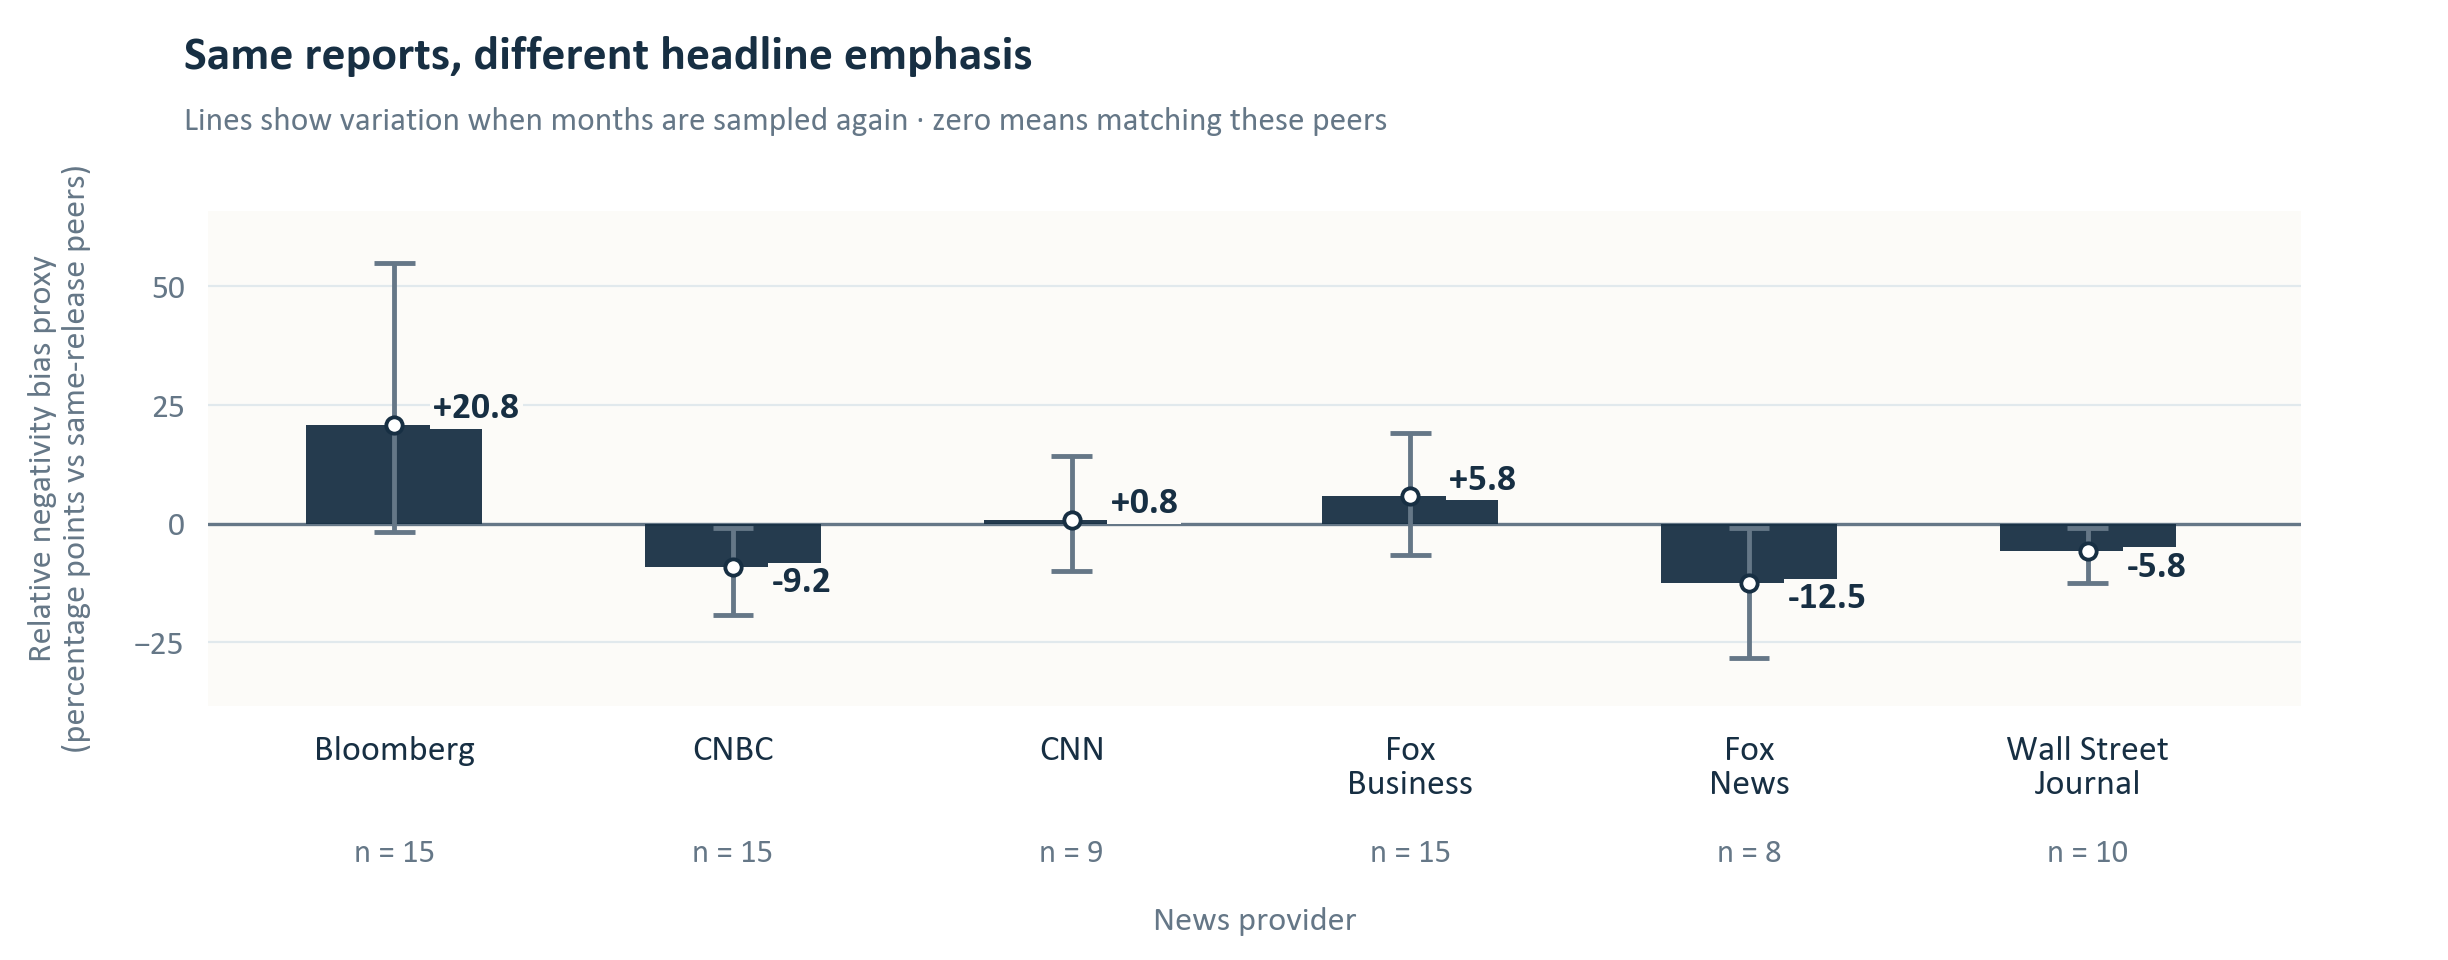

In [33]:
display(Image(filename=str(ROOT / 'outputs' / 'provider_bias.png')))

Same-event comparison: 6 providers, 6 reports and 72 headlines. The events are 5 jobs reports and 1 consumer-price report. Bars show extra negative-headline share compared with the other providers, in percentage points. Each report counts equally. The n labels count headlines. Lines show how results vary when the 6 months are repeatedly sampled; they leave out search and AI-label errors.

A provider with 40% negative headlines versus a 30% average for the others gets +10 percentage points: 40 minus 30. Zero means matching these peers, not perfect neutrality. Average within each provider/report first, compare with the other providers equally, then give each report equal weight. The lines show variation when months are sampled again; they omit search and AI-label errors.

The separate October 15, 2026 sample uses six providers and six shared reports. A documented change used coverage counts, not scores, after the original set shared only four. CNBC and the two Fox publications remain separate. Different truthful details can explain different wording; some signs change under other checks. Human validation is missing here, and the earlier AI review had no CNBC or Fox items. The bars do not measure lying, political loyalty or effects on readers.

This small provider sample is an explicit benchmark for relative framing, separate from the long monthly forecast corpus. It partly holds news events constant, but not which true components each outlet chooses to emphasize. An equivalent-surprise test would additionally require archived pre-release expectations. Realized good or bad outcomes cannot be relabeled as economic surprises without that information.

The score is negative-headline share minus the equally weighted mean for other sampled providers, then averaged equally across the common releases. A positive bar is extra negative wording relative to these peers. The 95% month-resampling ranges describe stability conditional on the captured titles and labels; they do not include retrieval or classifier error. Zero is a peer reference, not a universal neutral point.

The separate acquisition was October 15, 2026. Main economic information remains frozen October 13. October 23's final survey and October 29's BEA price/output releases are later updates; election timing alone establishes no cause. The dashboard retains release dates, source counts, forecast intervals and model comparisons.

## Part A / Answers, limitations and financial use

In [34]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[14][1][0]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Required question,What the evidence supports
0,How measure coverage bias?,"Compare the same events; separate tone, topics, framing, facts and..."
1,Impact on Michigan sentiment?,A forecasting link does not show that news caused the national sco...
2,How much does the economy explain?,The three inputs leave large errors; last month’s survey often pre...
3,Which thinking biases are measurable?,"We see wording, not readers’ attention, memory or beliefs. Individ..."
4,Do headlines improve predictions?,"Only tiny, statistically unreliable gains on matching test months."
5,What would contradict a media explanation?,"Household costs explaining the gap, accurate negative reporting, o..."


**What the study establishes.** It provides an auditable economic-data correction, chronological forecasting comparisons, a transparent national/local/social headline sample and an explicit same-release provider benchmark. Text measures add little predictive information here, and uncertainty does not establish a reliable improvement. A rigorous null can be useful: it prevents a story about biased readers or publishers from outrunning the evidence.

**What remains incomplete.** Two independent human annotators have not labeled the 300-item project packet. Content retrieval is retrospective, the contextual model postdates early titles, source composition changes, political and household microdata are unavailable, and no actual respondent exposure is observed. These limitations prevent a validated source ranking or causal national media estimate. A published external benchmark can help test model transfer but cannot remove these gaps.

**Financial implication.** Use a persistent model gap as a prompt to review household purchasing power, uncertainty, survey methods and new releases before changing a consumer-demand scenario. The aggressive wording-only rules are fully reported in the appendices and notebook: two made money historically, all three lagged ordinary stocks and suffered deeper falls. There is no established profitable trading edge.

**Reproduction and ethics.** The executed notebook recomputes estimates from frozen local inputs; the source repository and submission archive include code, aggregate outputs, exact versions and protocols. Raw/derived item data and model weights remain local under the project's established policy. Source access, attribution and restrictions are recorded in docs/DATA_ACCESS_AND_ETHICS.md. No participants were recruited, trades placed or national intelligence scores inferred.

Part B now changes the object of inquiry from published wording to the conditions that help readers judge truth. Its manifesto is an explicitly labeled argument, backed and challenged by independent literature. It is not an empirical conclusion that the Michigan gap was caused by declining intelligence.

## Part B / A manifesto for independent judgment

**The scarce resource is independent judgment.** An endless supply of information is of little use if we stop asking how anyone knows what they claim. We can count a publisher's negative headlines and still miss the deeper problem: a reader may confuse a confident sentence with evidence, a familiar story with truth, or an effortless answer with understanding. Part A did not measure readers' abilities. This manifesto makes a broader argument, informed by the research examined on the following pages.

We should demand more from ourselves than finding a source that agrees with us. Before repeating an alarming economic claim, find the original release, check its date and units, and ask what would change your mind. A falling inflation rate can coexist with an expensive shopping basket. A negative headline can be accurate. A comforting headline can be misleading. Critical thinking means applying the same standard to both.

**Let tools support thought without replacing practice.** Ask AI for questions, explanations and competing interpretations. Then close the tool and explain the reasoning yourself. If we can reproduce an answer but cannot justify it, we have gained a product without necessarily gaining a skill. Schools and workplaces should assess unaided understanding alongside assisted performance. A helpful system should make the person more capable next time.

**Treat attention as something worth protecting.** Leave room for long explanations, inconvenient evidence and the pause before sharing. Platforms should make an original source and a correction easy to find. A design that rewards immediate reaction may make careful checking harder; that is a testable concern about incentives, not proof that every user has lost intelligence. Readers also need time and resources to think, not merely instructions to try harder.

**Build ability across generations.** Decisions about children belong to the people making them. Financial insecurity, schooling, health, housing and access to family planning deserve serious attention. Country averages and family size cannot tell us a person's intelligence or worth. A credible argument for the future invests in children's opportunities and adults' capacity to judge evidence, rather than sorting families into supposedly superior and inferior kinds.

The risk is a loss of practiced reasoning and reliable institutions: more decisions made with confidence that exceeds understanding. Such a setback could damage education, public debate and financial judgment without any demonstrated genetic decline. It is a possible social outcome, not an inevitable biological destiny. The response is to make verification a habit, preserve learning, and test whether our interventions work.

**Status of this part.** These are normative commitments: statements about what we should value and do. The next pages test their factual premises against primary research, include contrary evidence, and propose measurements that could prove the argument wrong. The original headline study does not establish a global fall in IQ, a decline caused by social media, or a demographic cause of cognitive change.

## B1. Is the world becoming less intelligent?

Intelligence quotient (IQ) is a standardized test score, normally compared with an age group. A historical trend needs comparable tasks and consistent reference norms; a test renormed to an average of 100 cannot itself be read as a world time series. IQ, factual knowledge, attention, reasoning practice and the ability to check a news claim are related ideas, but they are different measurements.

In [35]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[16][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Evidence,What it supports,What it does not establish
0,Historical gains [B1],"A meta-analysis of 271 samples, almost 4 million people and 31 cou...",A representative annual IQ series for every country or a guarantee...
1,A reversal in Norway [B2],Male birth cohorts 1962-1991 show a rise and later decline in test...,"A worldwide decline, or a claim that changing fertility between fa..."
2,Education-related genetic score [B3],"In Iceland, a score associated with educational attainment was lin...","A global IQ forecast, an intelligence ranking of income groups, or..."
3,Financial scarcity [B4],Financial concerns and pre/post-harvest conditions can affect perf...,That poverty identifies a person's fixed ability or explains all i...


The Norwegian comparison is especially relevant to the fertility argument. Siblings share many family characteristics, yet differences within families reproduce the overall rise and fall. For those cohorts, the authors' evidence favors environmental explanations over changes in which families reproduce. It does not identify a single environmental cause, and a study of Norwegian men cannot describe all of humanity. [Bratsberg and Rogeberg, 2018](https://doi.org/10.1073/pnas.1718793115).

The Icelandic study is relevant evidence for a narrower concern about selection: it examines reproductive histories of 109,120 people and finds a change in an education-related genetic score across birth cohorts. That score captures only part of a complex trait in a particular population and setting. It is not a measurement of every child's intelligence, nor a license to project country fertility differences into a worldwide cognitive collapse. [Kong et al., 2017](https://doi.org/10.1073/pnas.1612113114).

The defensible conclusion is that some measured cognitive performances can decline under particular conditions. The stronger claim that world IQ keeps falling is not established by this evidence. Evolution describes changes in populations, without a universal ladder from worse to better. A loss of learning or critical-thinking habits would be a serious social problem even without a demonstrated evolutionary reversal. [UC Berkeley](https://evolution.berkeley.edu/evolution-101/the-big-issues/trends-in-evolution/).

Other primary sources: [Pietschnig and Voracek, 2015](https://doi.org/10.1177/1745691615577701); [Mani et al., 2013](https://doi.org/10.1126/science.1238041). The latter supports a situational pathway, not a universal estimate of poverty's effect or a claim about innate ability.

## B2.1 Birth rates / Ranks 1-20

These five bar charts show the 100 highest available **birth rates in 2023**, in descending order. Every entry uses the same year and every chart uses the same horizontal scale starting at zero. The World Bank reports countries and economies, including some separately reported territories. Regional, world and income-group aggregates are excluded; missing observations are not assigned zero.

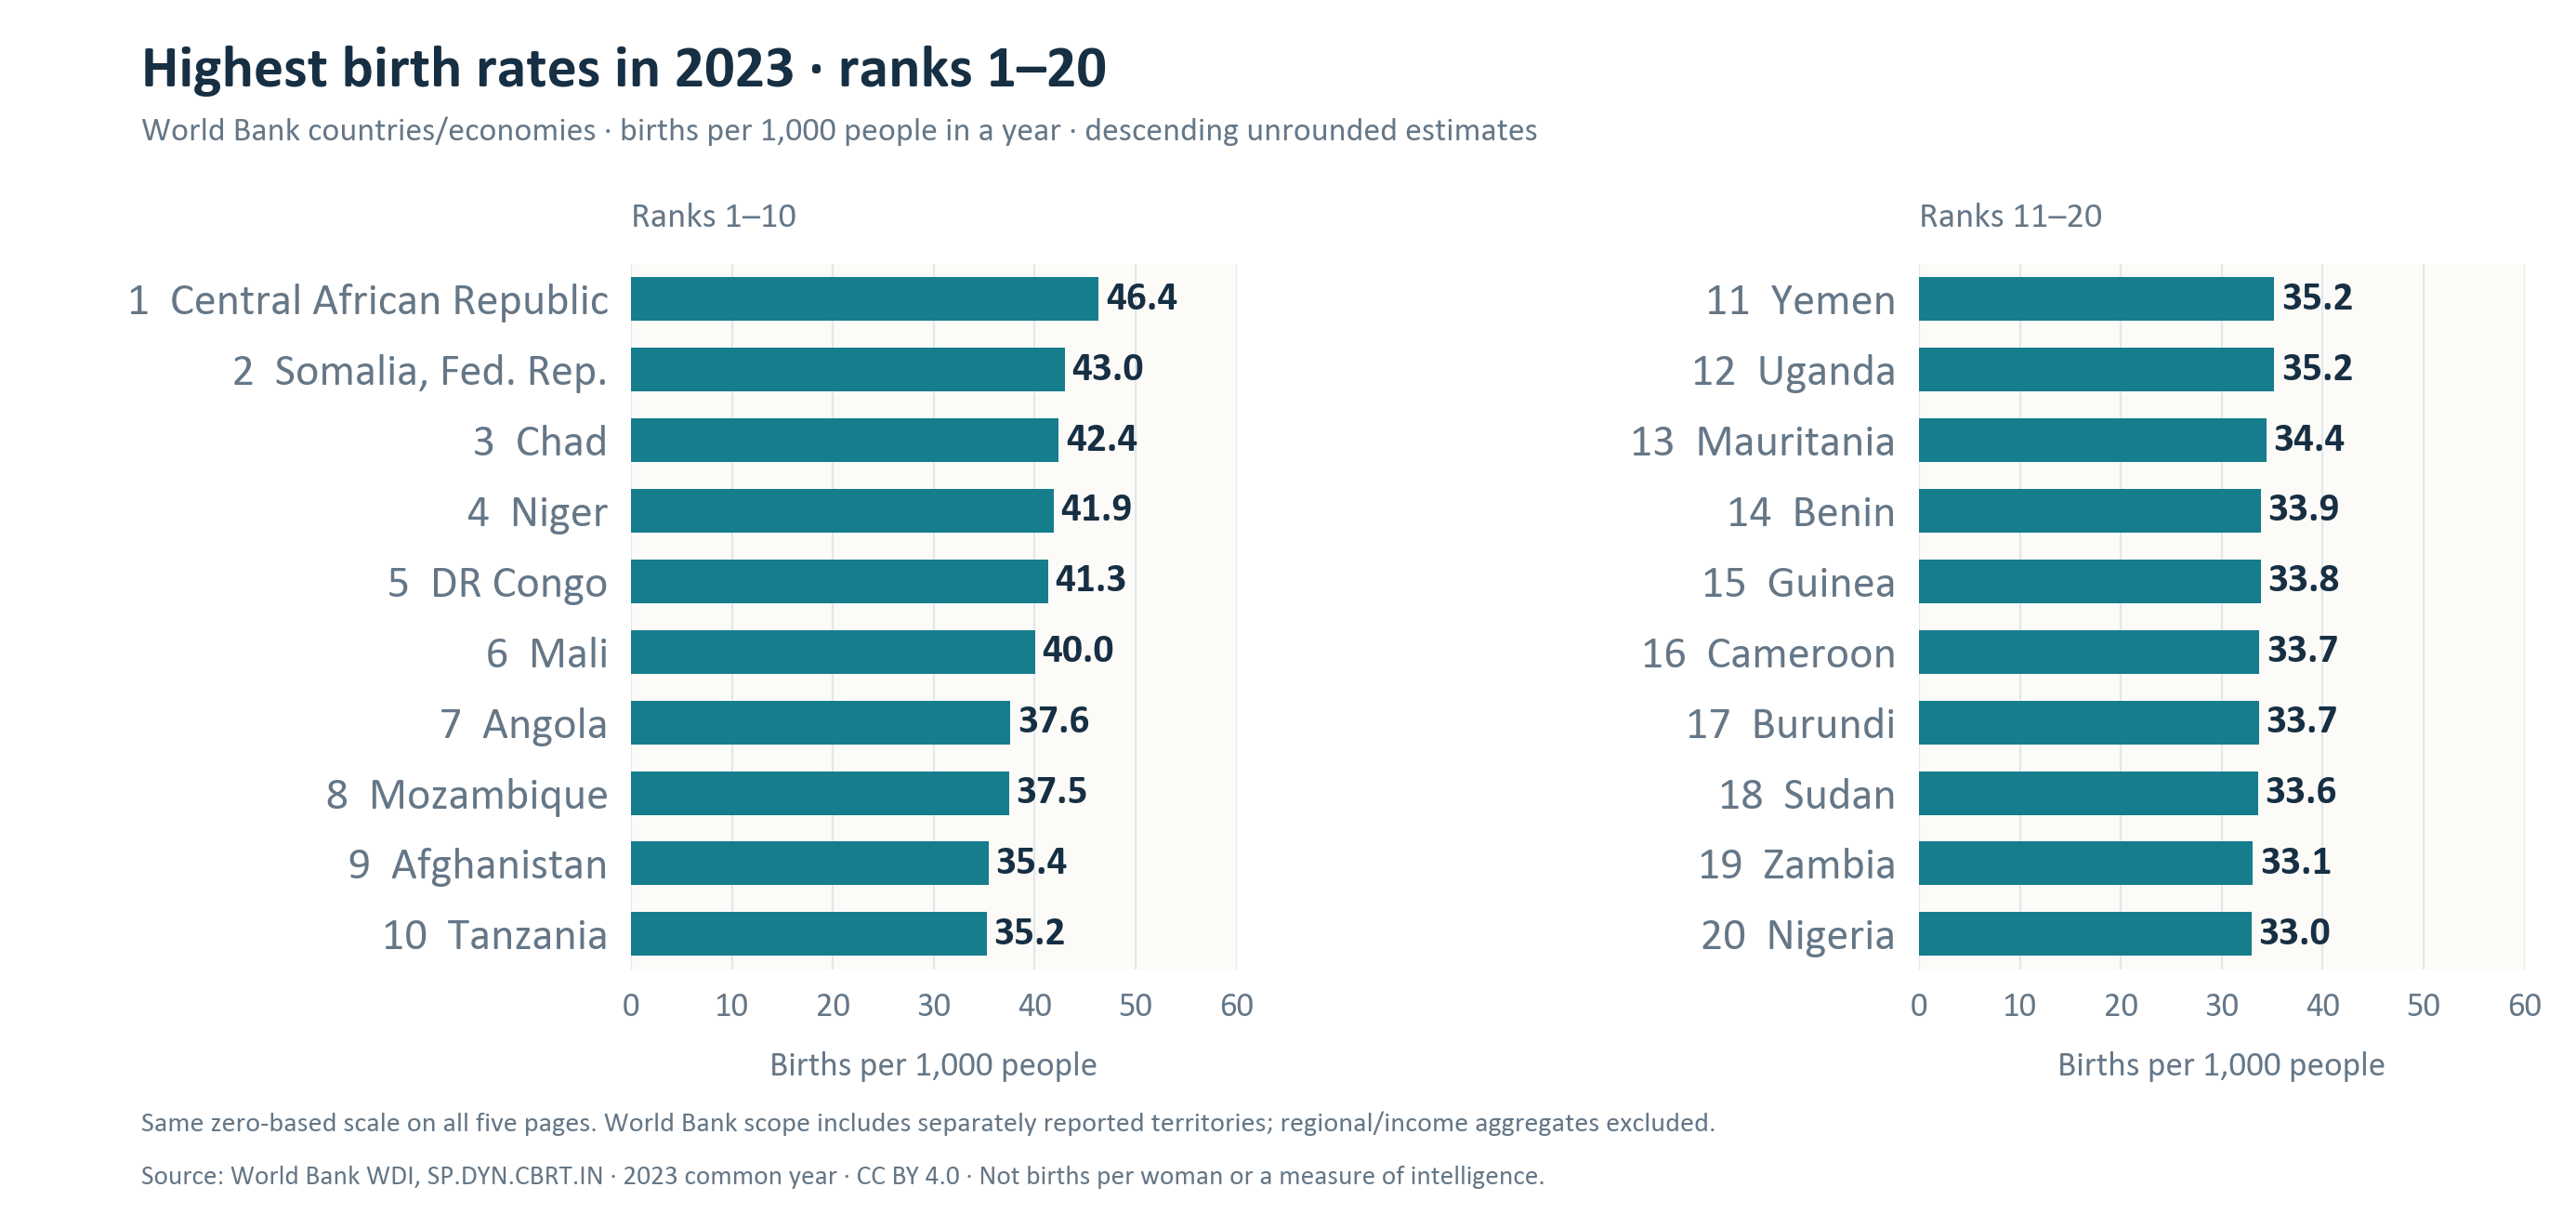

In [36]:
display(Image(filename=str(ROOT / 'outputs' / 'country_birth_rates_01.png')))

Ranks 1-20 of the 100 highest reported 2023 country/economy birth rates. Bars show annual births per 1,000 people, not total births. Values are rounded for display; ranking uses unrounded observations. Source: World Bank WDI, SP.DYN.CBRT.IN.

**How to read a bar.** A rate of 40 means about 40 births in one year for every 1,000 people: about 4%, not 40%. Population age structure affects this measure. It differs from **total fertility rate**, the period estimate of births per woman used in the following income-group chart.

The ranking describes births, not intelligence or individual behavior. A country average cannot show why particular people have children. The figures are historical estimates from the October 2026 download, not forecasts. [World Bank definition and source data](https://data.worldbank.org/indicator/SP.DYN.CBRT.IN).

## B2.2 Birth rates / Ranks 21-40

The descending ranking continues with places 21-40. Read the left panel from top to bottom, then the right panel. The global rank is printed beside each name; all five charts use the same scale.

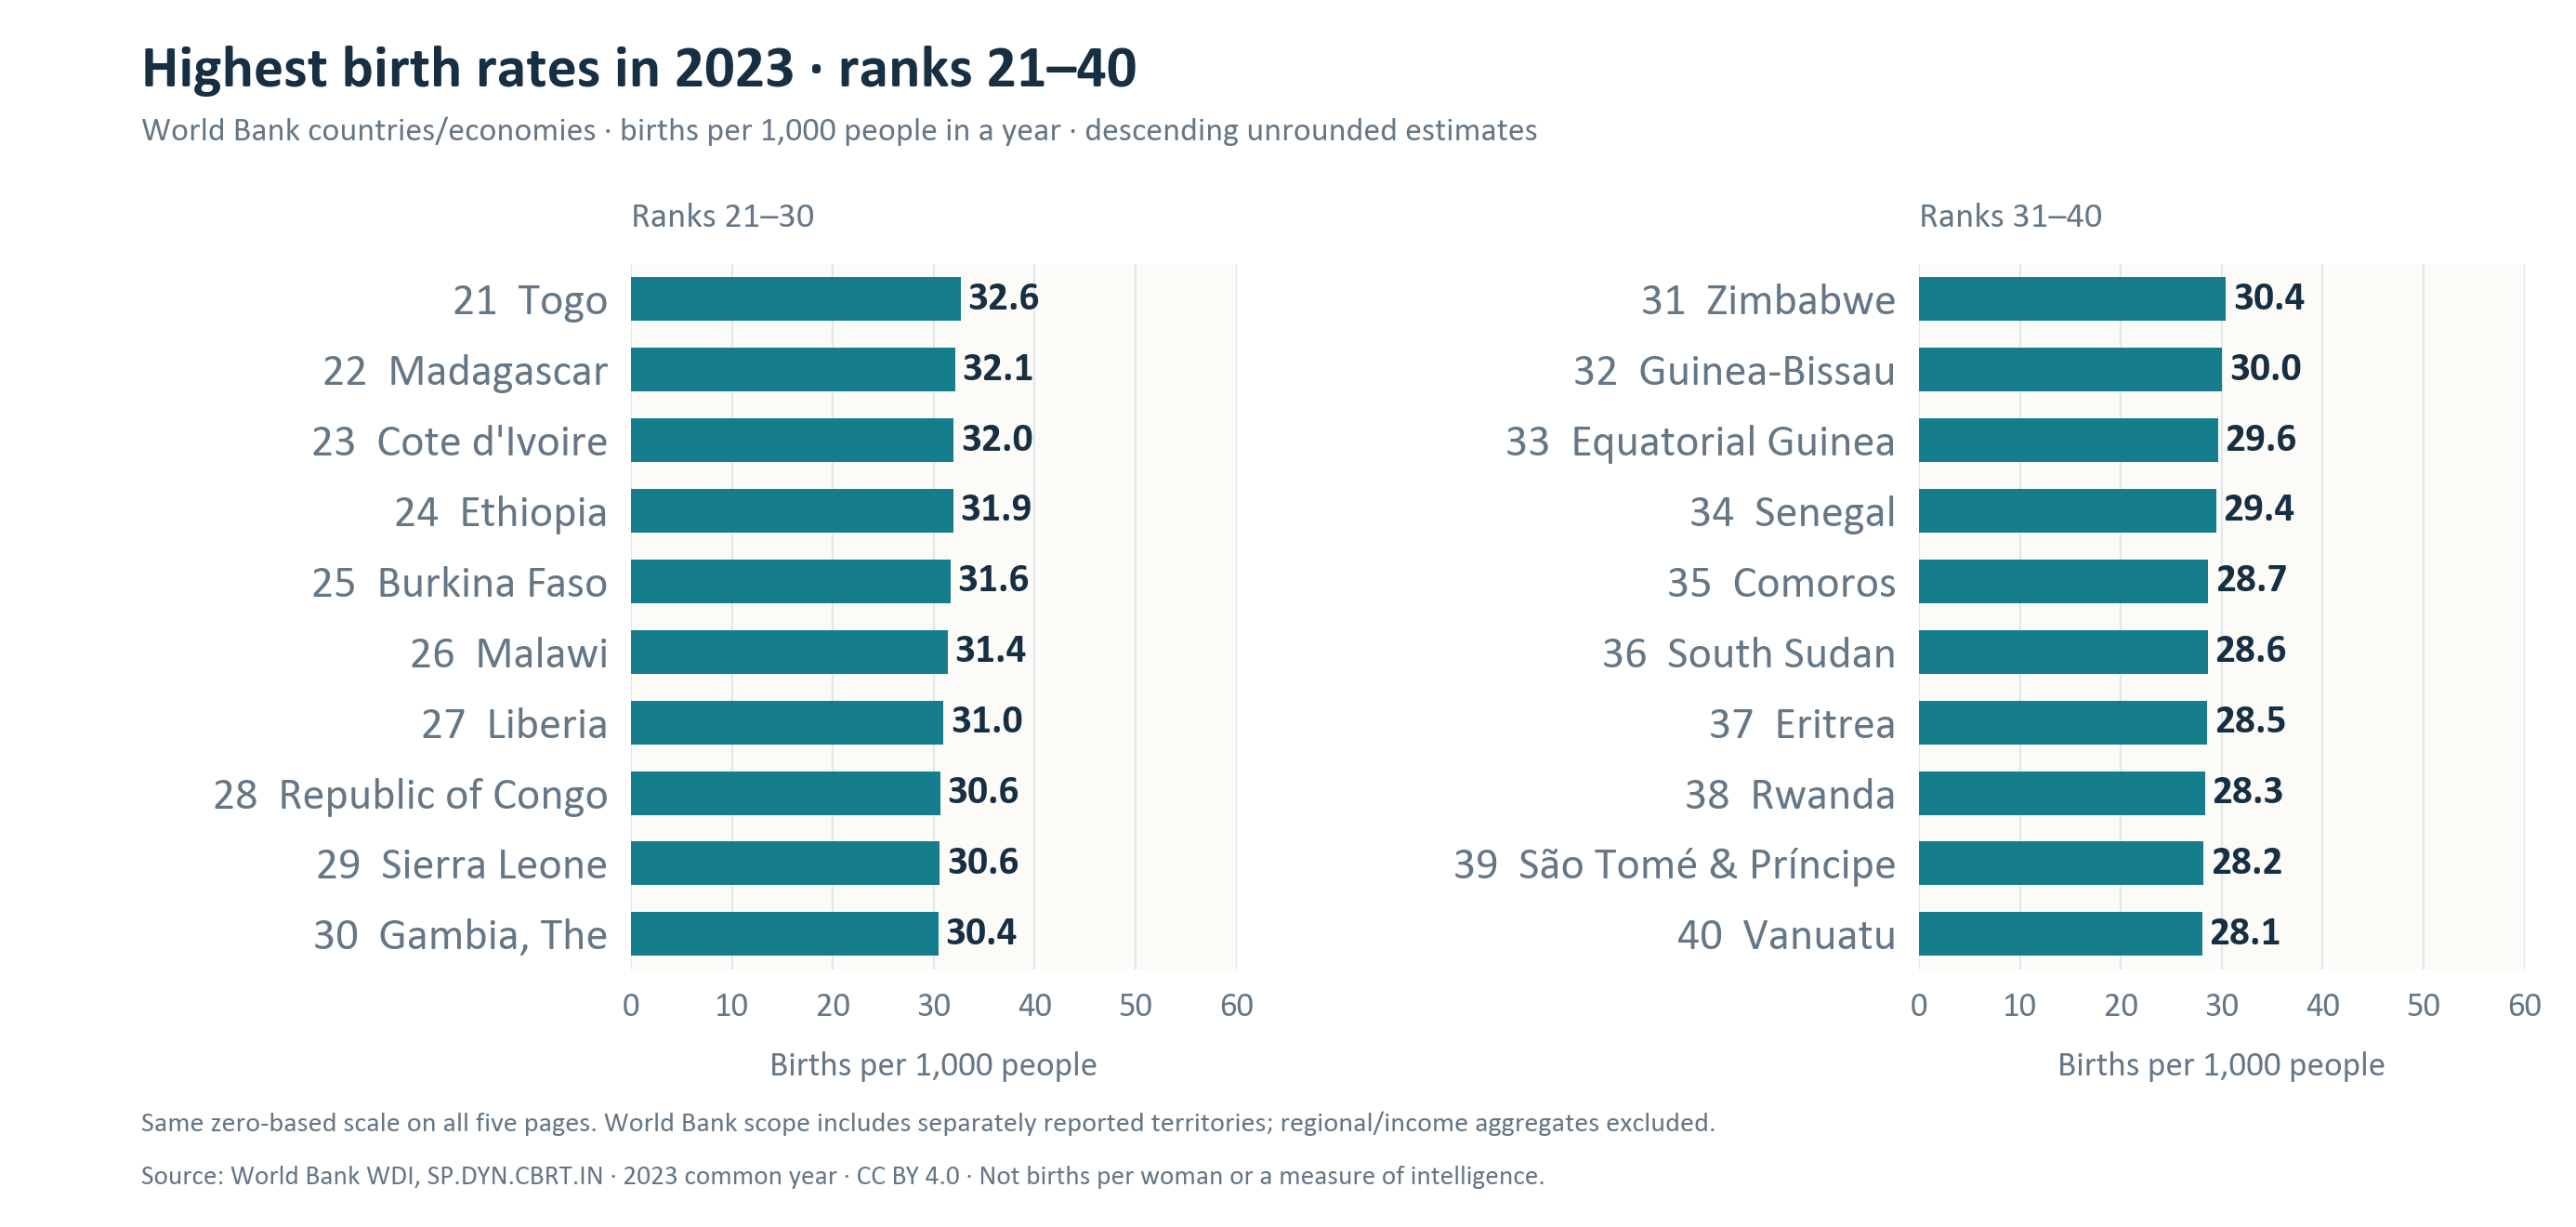

In [37]:
display(Image(filename=str(ROOT / 'outputs' / 'country_birth_rates_02.png')))

Ranks 21-40 of the 100 highest reported 2023 country/economy birth rates. Bars show annual births per 1,000 people, not total births. Values are rounded for display; ranking uses unrounded observations. Source: World Bank WDI, SP.DYN.CBRT.IN.

A longer bar means more births relative to population size, not necessarily more births in total. Country/economy coverage follows World Bank reporting; it is not a claim that every listed entry is a sovereign state. [Indicator definition and sources](https://data.worldbank.org/indicator/SP.DYN.CBRT.IN).

## B2.3 Birth rates / Ranks 41-60

The descending ranking continues with places 41-60. Read the left panel from top to bottom, then the right panel. The global rank is printed beside each name; all five charts use the same scale.

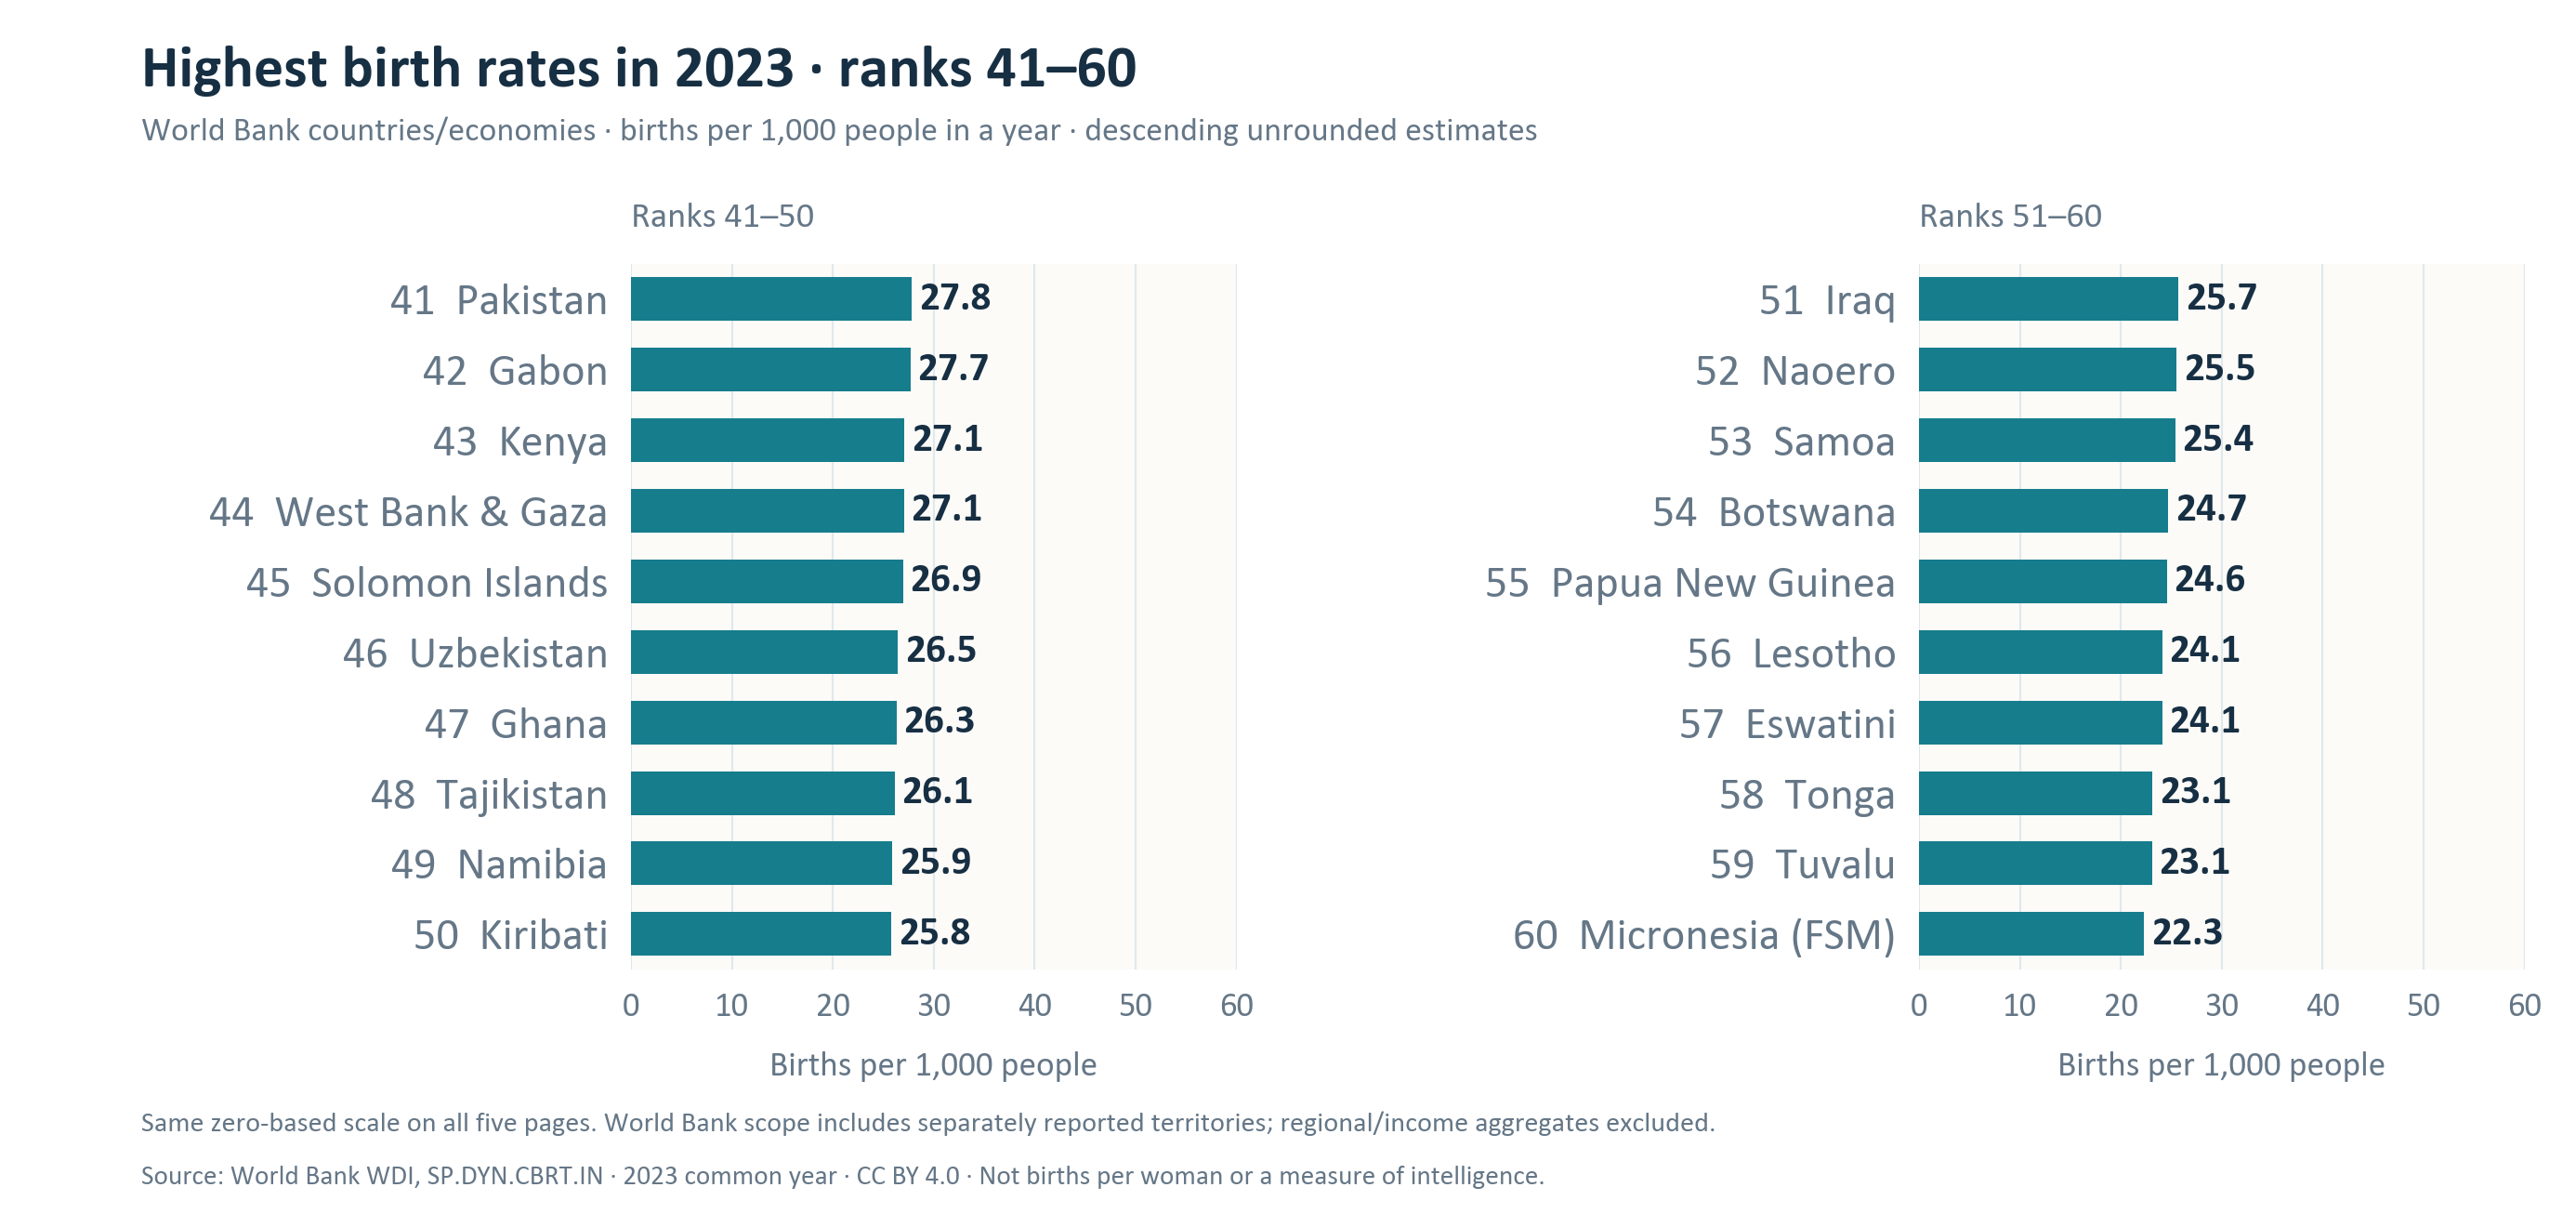

In [38]:
display(Image(filename=str(ROOT / 'outputs' / 'country_birth_rates_03.png')))

Ranks 41-60 of the 100 highest reported 2023 country/economy birth rates. Bars show annual births per 1,000 people, not total births. Values are rounded for display; ranking uses unrounded observations. Source: World Bank WDI, SP.DYN.CBRT.IN.

A longer bar means more births relative to population size, not necessarily more births in total. Country/economy coverage follows World Bank reporting; it is not a claim that every listed entry is a sovereign state. [Indicator definition and sources](https://data.worldbank.org/indicator/SP.DYN.CBRT.IN).

## B2.4 Birth rates / Ranks 61-80

The descending ranking continues with places 61-80. Read the left panel from top to bottom, then the right panel. The global rank is printed beside each name; all five charts use the same scale.

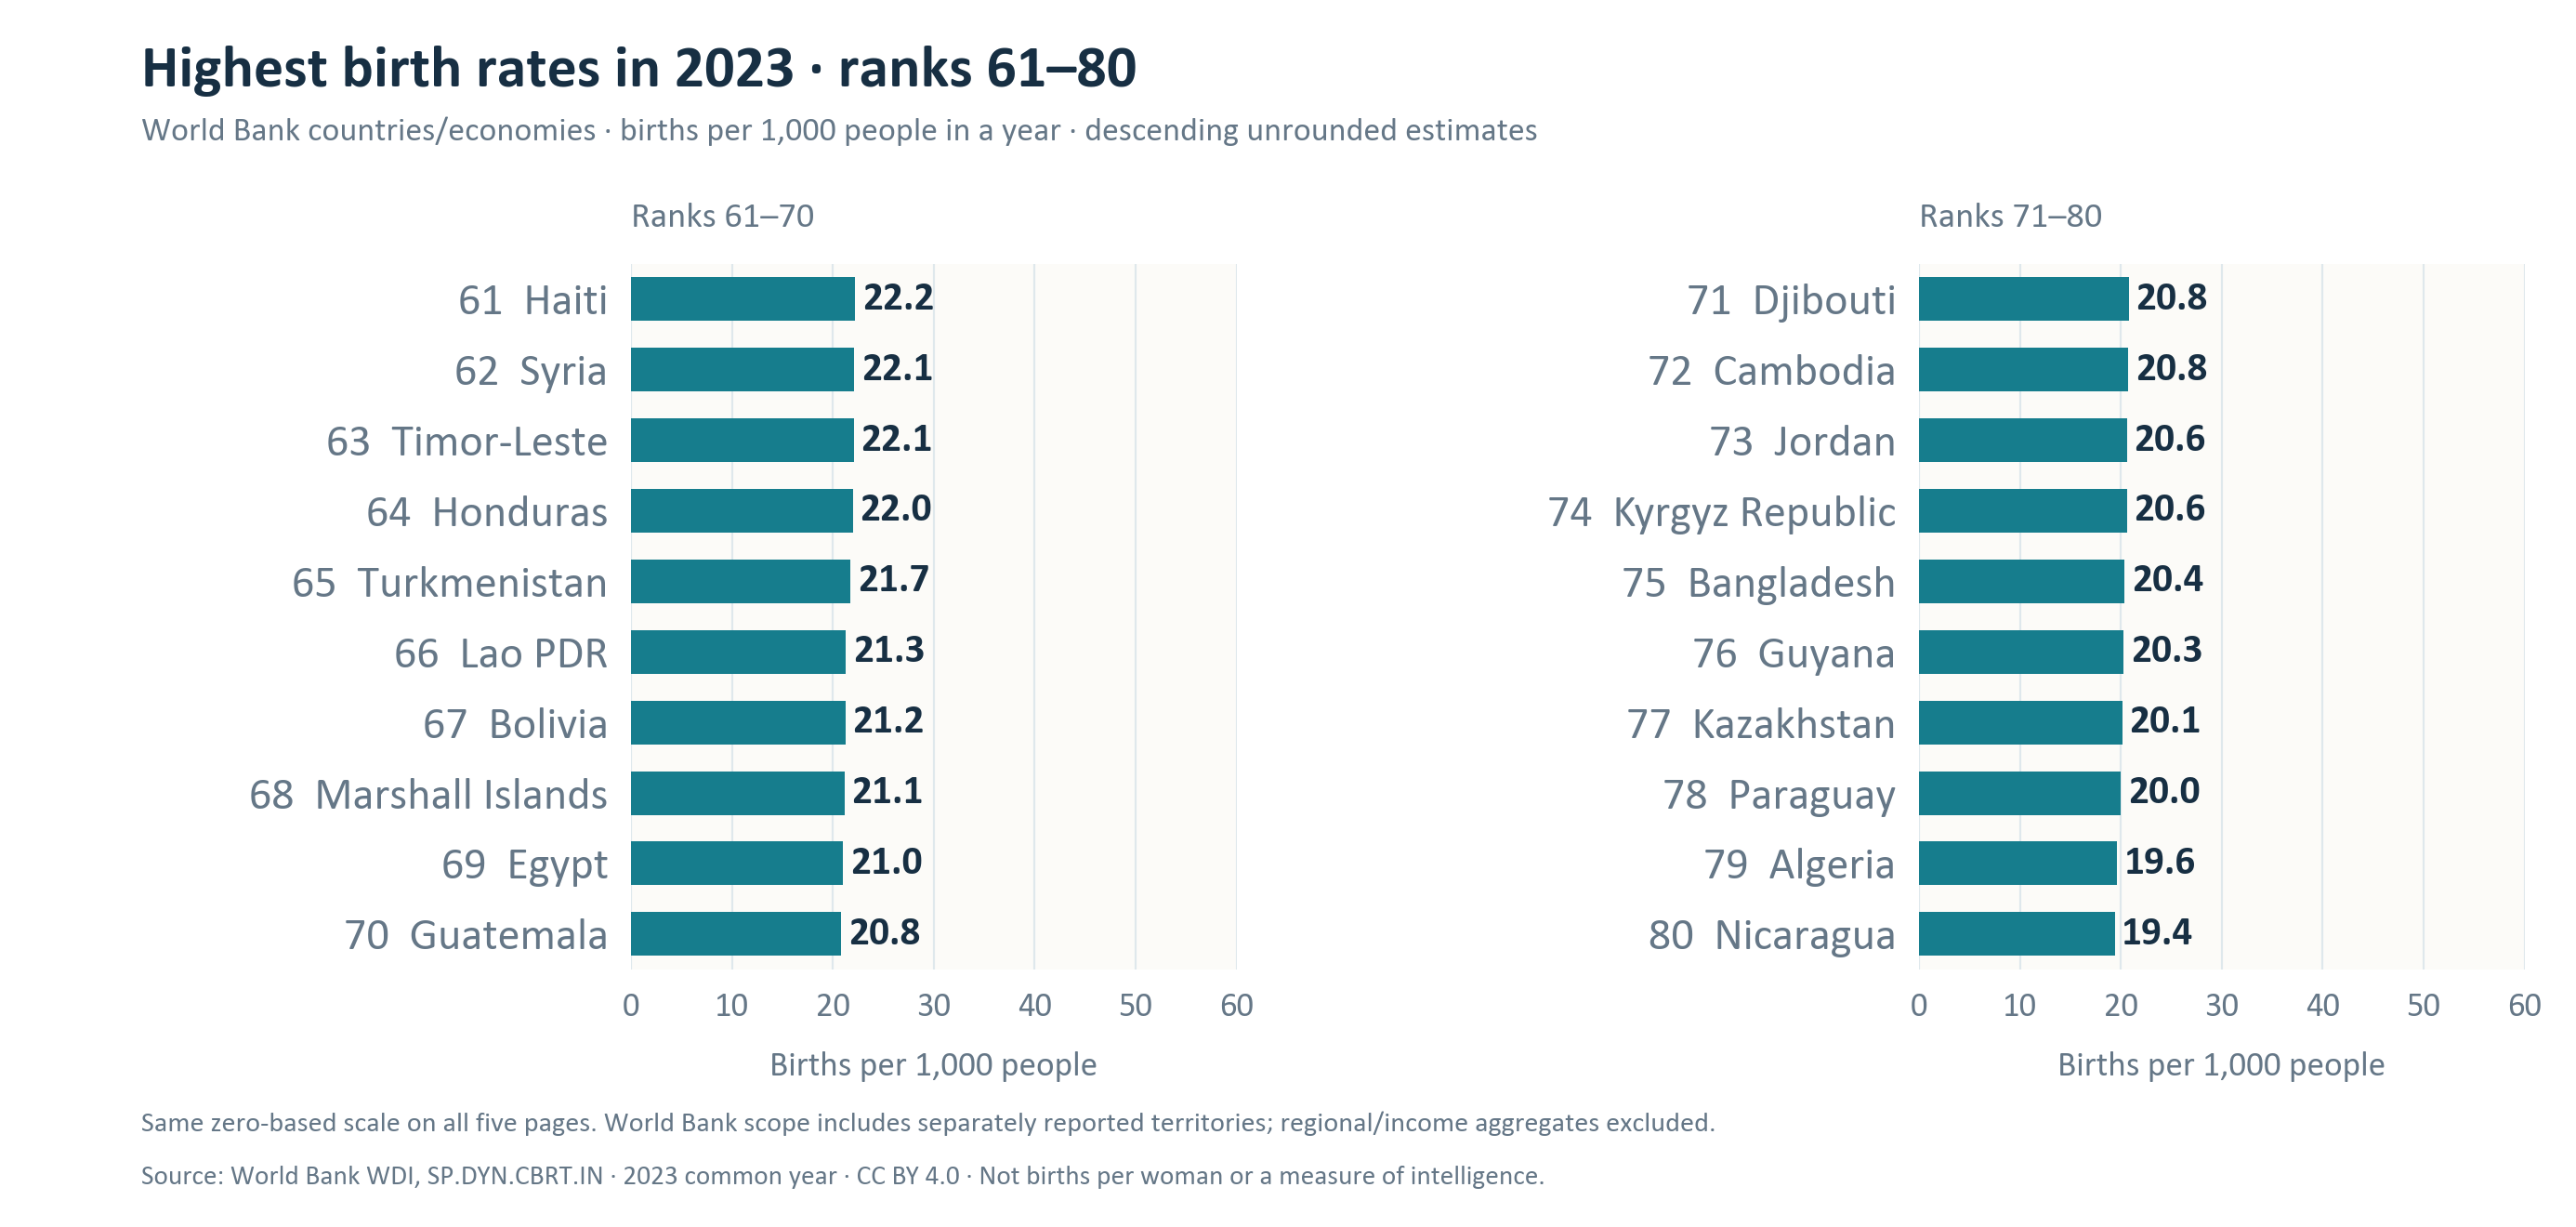

In [39]:
display(Image(filename=str(ROOT / 'outputs' / 'country_birth_rates_04.png')))

Ranks 61-80 of the 100 highest reported 2023 country/economy birth rates. Bars show annual births per 1,000 people, not total births. Values are rounded for display; ranking uses unrounded observations. Source: World Bank WDI, SP.DYN.CBRT.IN.

A longer bar means more births relative to population size, not necessarily more births in total. Country/economy coverage follows World Bank reporting; it is not a claim that every listed entry is a sovereign state. [Indicator definition and sources](https://data.worldbank.org/indicator/SP.DYN.CBRT.IN).

## B2.5 Birth rates / Ranks 81-100

The descending ranking continues with places 81-100. Read the left panel from top to bottom, then the right panel. The global rank is printed beside each name; all five charts use the same scale.

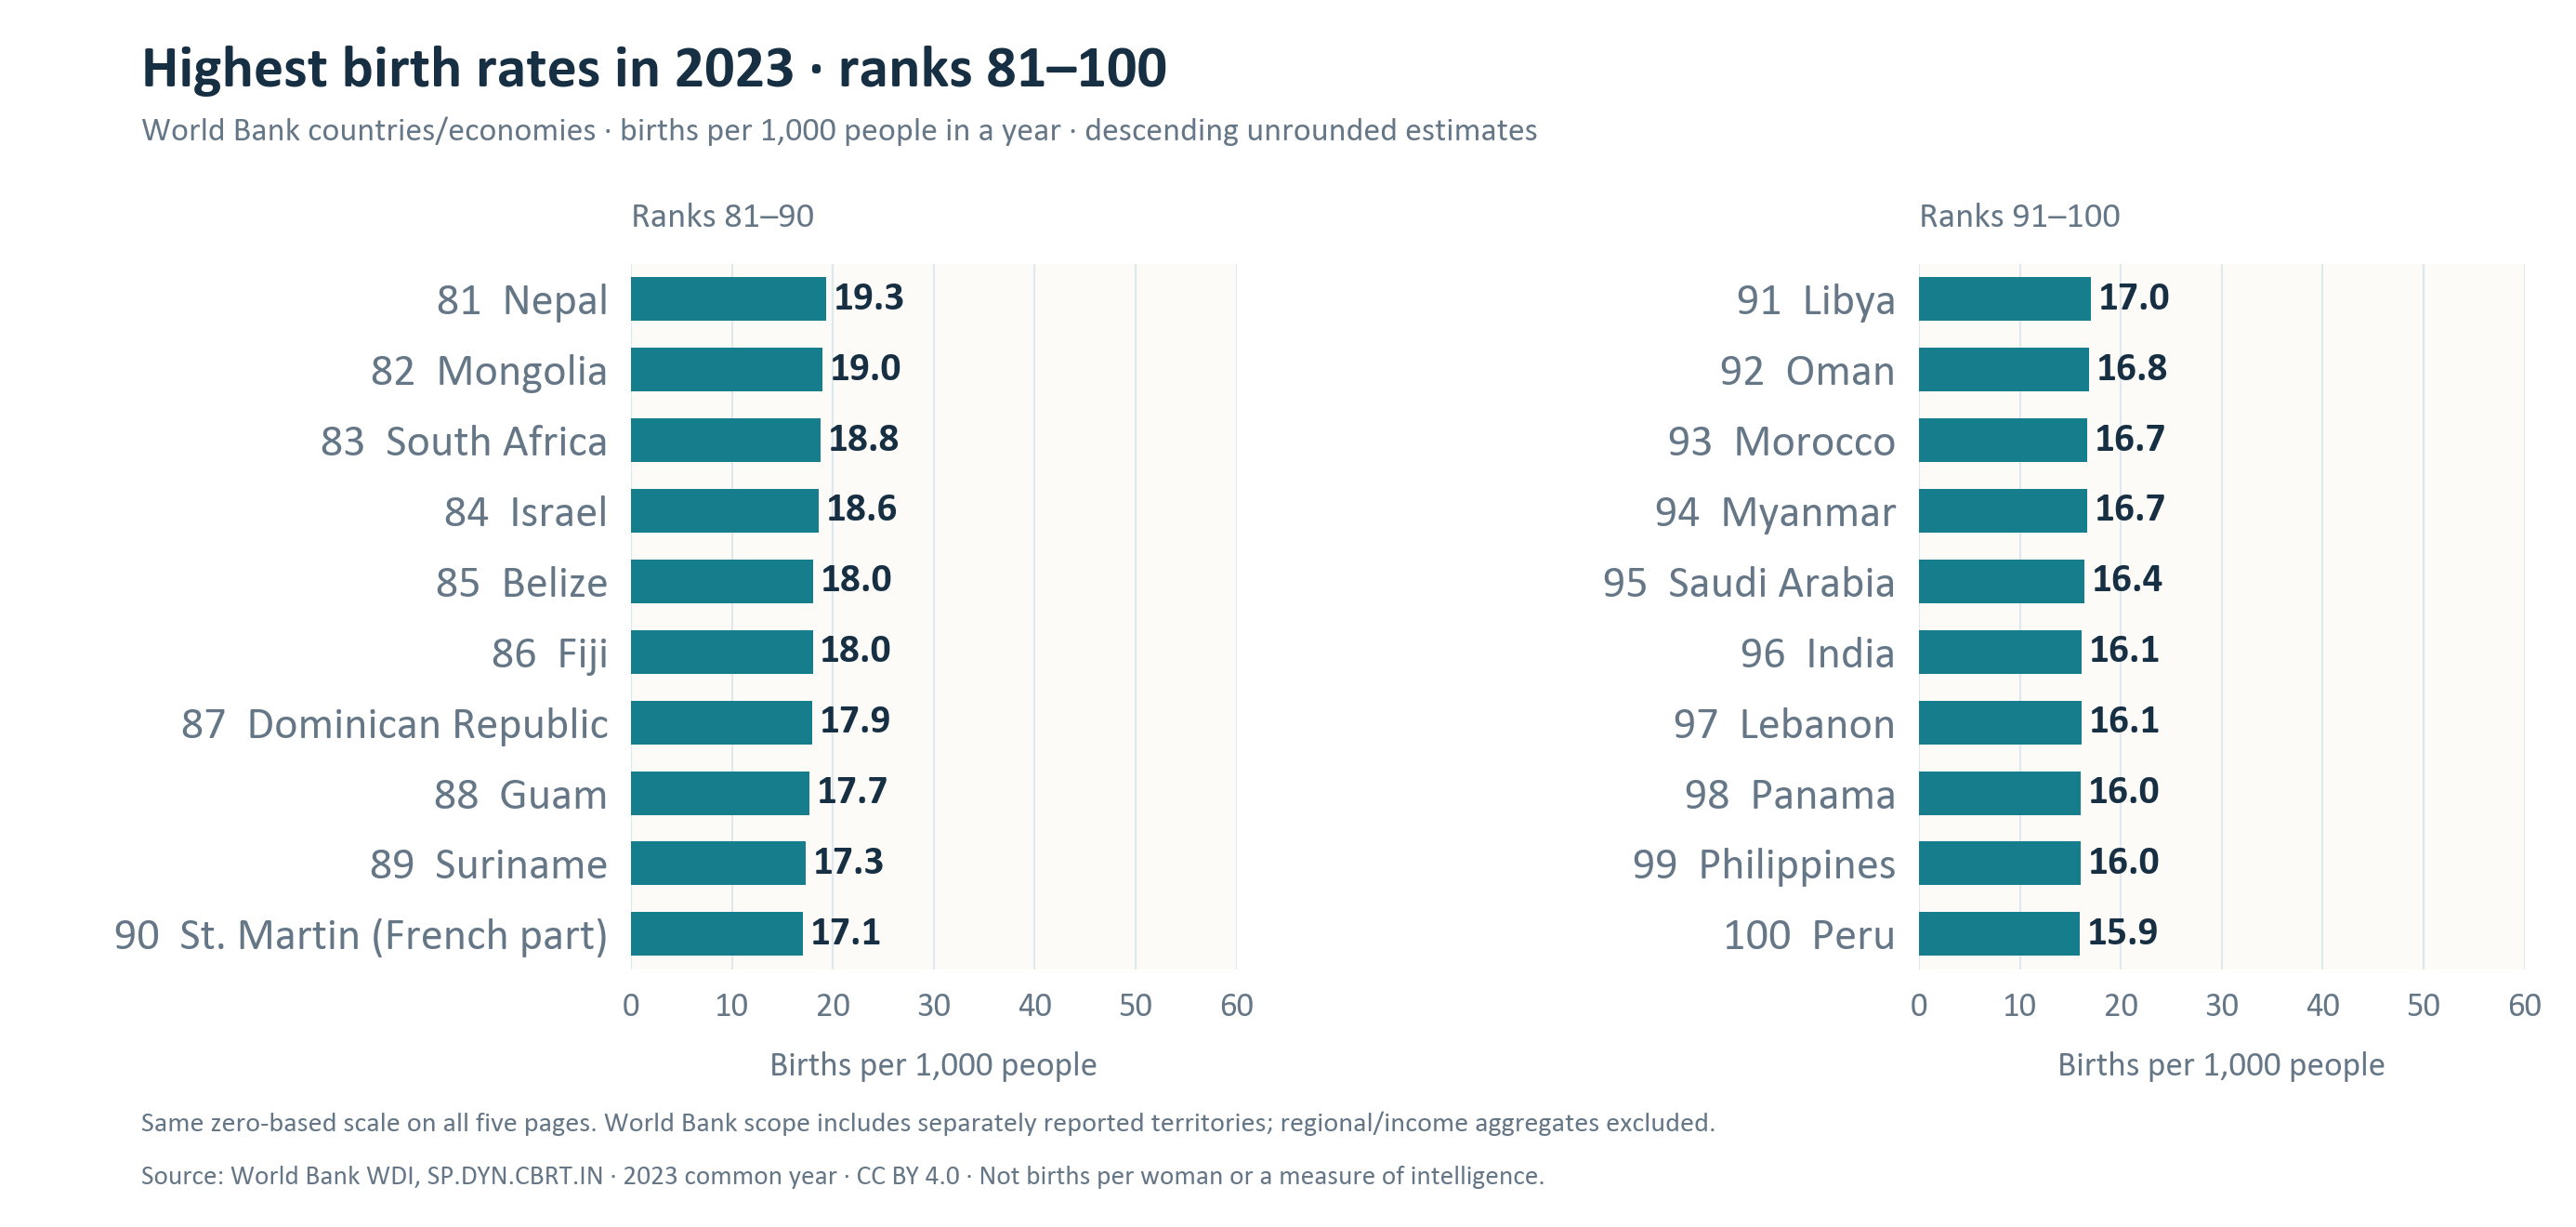

In [40]:
display(Image(filename=str(ROOT / 'outputs' / 'country_birth_rates_05.png')))

Ranks 81-100 of the 100 highest reported 2023 country/economy birth rates. Bars show annual births per 1,000 people, not total births. Values are rounded for display; ranking uses unrounded observations. Source: World Bank WDI, SP.DYN.CBRT.IN.

A longer bar means more births relative to population size, not necessarily more births in total. Country/economy coverage follows World Bank reporting; it is not a claim that every listed entry is a sovereign state. [Indicator definition and sources](https://data.worldbank.org/indicator/SP.DYN.CBRT.IN).

## B3. Financial security and the next generation

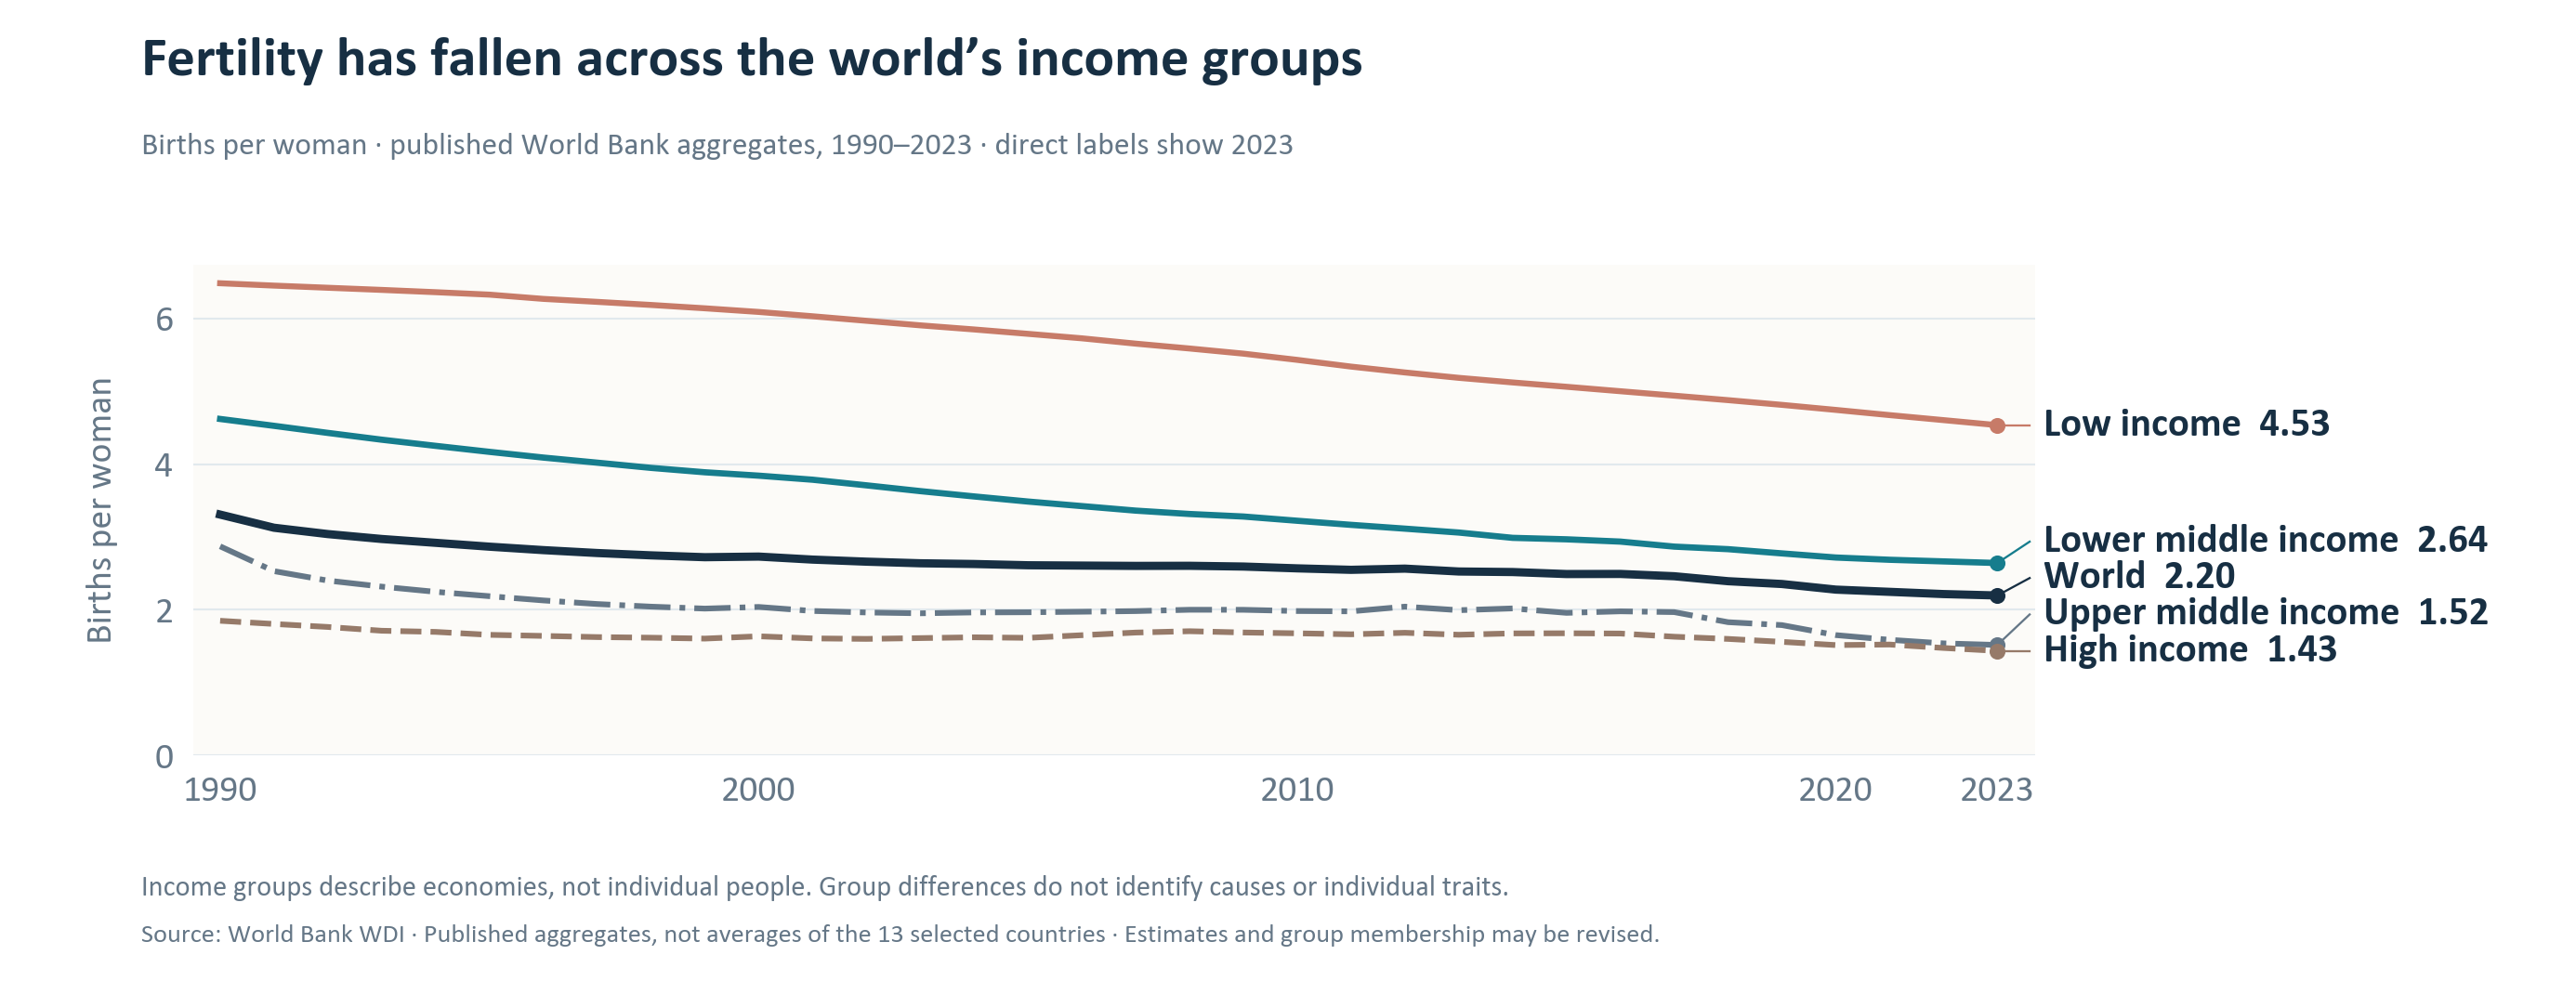

In [41]:
display(Image(filename=str(ROOT / 'outputs' / 'part_b_fertility_trends.png')))

Annual period fertility, 1990-2023. The world and income aggregates are population-level summaries using the World Bank grouping in this snapshot; classifications can change. These lines measure births per woman, not intelligence or completed family sizes.

Economic planning before parenthood is a real concern, but it cannot be assigned only to an allegedly smarter class. UNFPA's 2025 survey across 14 countries found financial limits were commonly reported as obstacles to the desired family size. Its reported 39% is a survey summary across those countries, not a census of all adults worldwide. The question concerns constraints and aspirations, not IQ. [UNFPA, State of World Population 2025](https://www.unfpa.org/swp2025).

Country-level fertility patterns can reflect different combinations of schooling, access to contraception, child survival, marriage patterns, income security and the costs of raising children. The chart does not estimate the contribution of any one explanation. An assertion that poor families routinely have "tens of children" is not supported by these averages. More births per woman is also different from faster growth in the share of children who lack educational opportunities.

In [42]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[22][1][3]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Question worth asking,Evidence needed
0,Do financial constraints delay wanted births?,"Individual survey answers and timing of income, housing costs and ..."
1,Are children getting the support needed to learn?,"Comparable measures of nutrition, health, schooling and learning a..."
2,Could population change affect future skills?,"A transparent cohort model with education, health, migration and u..."


The manifesto's position is to reduce barriers to wanted families and strengthen every child's development. That is a value judgment. These fertility observations neither prove a genetic mechanism nor justify deciding whose children should exist. Their financial relevance is through possible changes in labor supply, education demand and household costs, which require separate forecasts.

## B4. AI can improve output while weakening practice

A classroom-randomized study in one Turkish high school compared ordinary resources, a standard AI assistant and a tutor designed to offer teacher-informed hints. AI improved assisted practice. When students later worked without it, the standard-assistant group scored lower than the control group; the hint-based tutor largely avoided that penalty. This is evidence that tool design matters for short-term learning. [Bastani et al., 2025](https://doi.org/10.1073/pnas.2422633122).

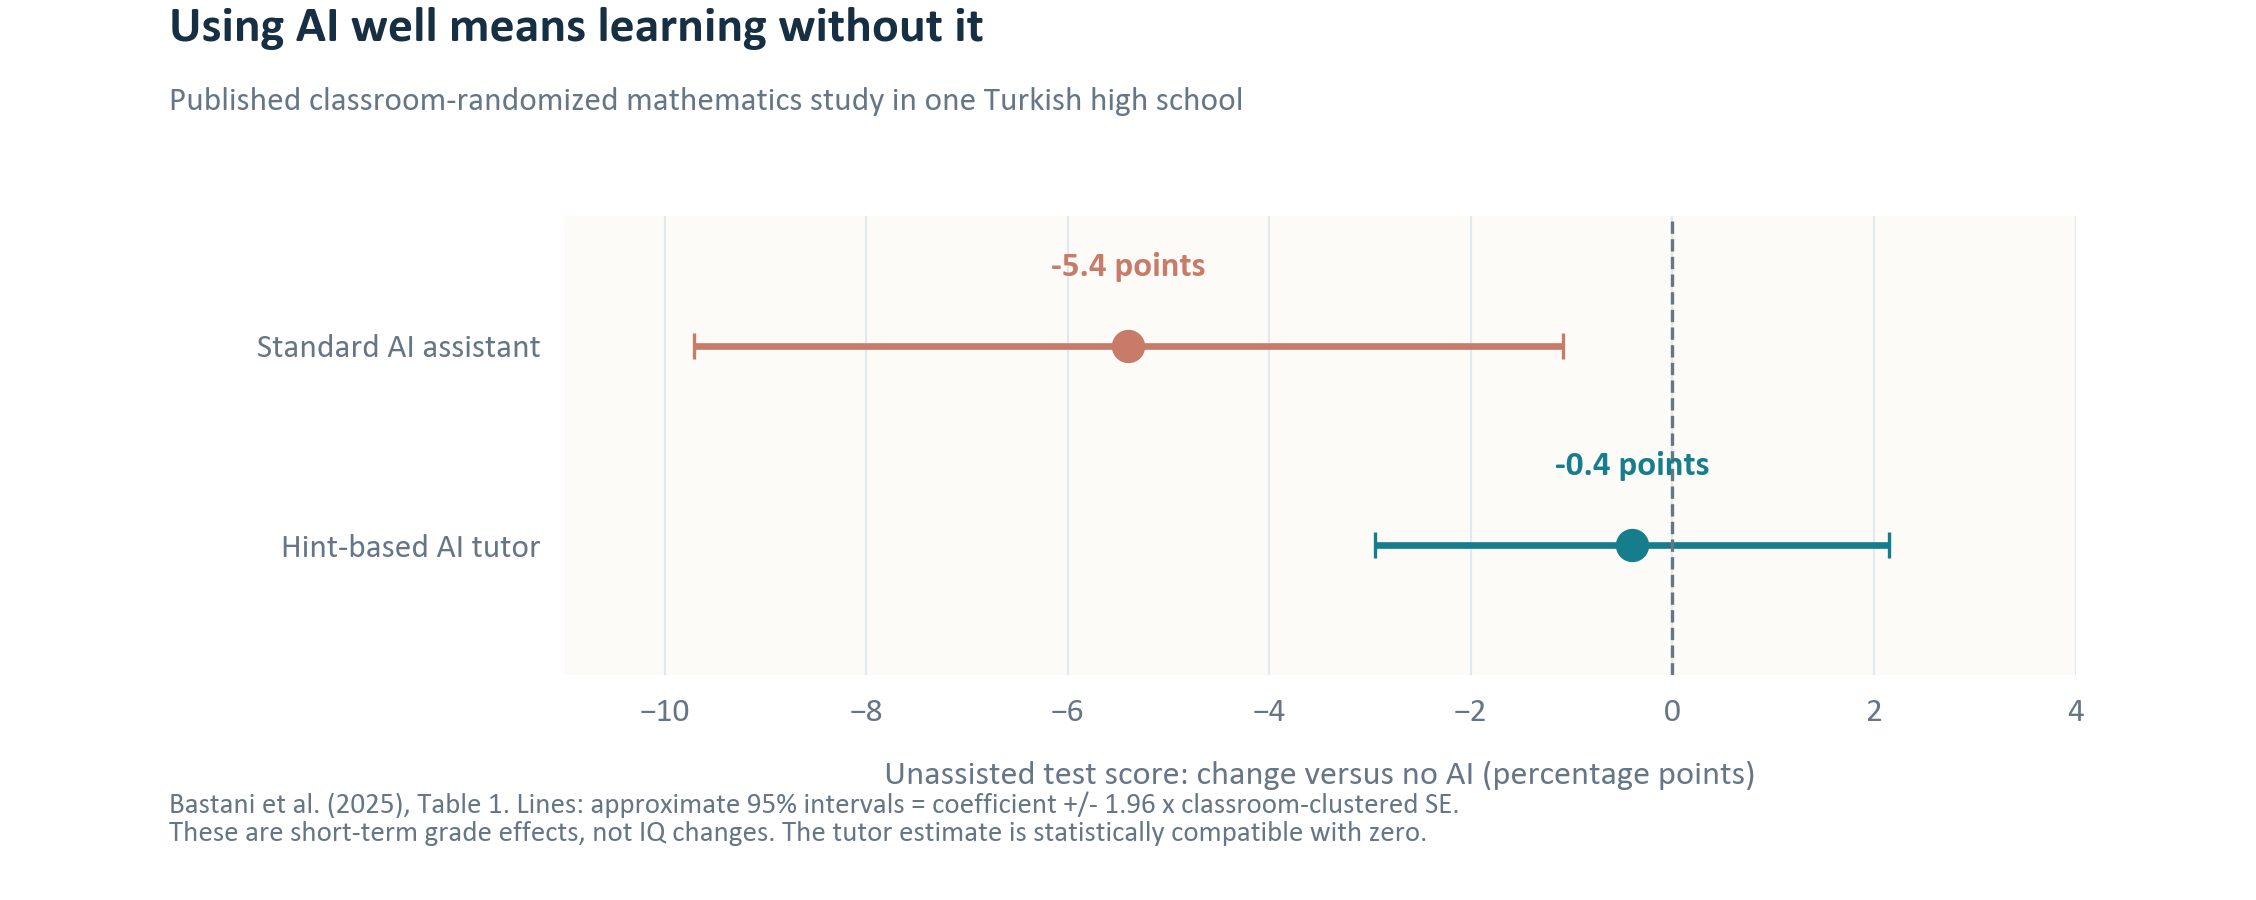

In [43]:
display(Image(filename=str(ROOT / 'outputs' / 'reader_ai_learning.png')))

Original chart of published Table 1 estimates. Scores were normalized from 0 to 1 and converted here to percentage points. The control test mean was 32.1%; -5.4 points is about 17% lower relative to that mean, not a 17-point fall. Intervals use a normal approximation to the reported clustered standard errors.

The study evaluates mathematics learning in a particular school and setting. It does not measure a permanent IQ loss, all AI products, or the long-term effect on the world. The tutor's estimate is compatible with no difference from control; that is not proof the tutor improved unaided learning. These boundaries matter when turning a memorable experiment into a broad argument.

**Our inference.** If an assistant repeatedly removes the need to retrieve, explain and check, a user may get fewer chances to practice those skills. That is a plausible mechanism to test in economic-news reading, not a result already obtained here. A person who uses AI to compare sources and challenge an answer might instead improve. Output quality and the user's later unaided understanding must be measured separately.

**A practical commitment.** Before accepting an AI explanation of inflation or an investment idea, attempt an answer yourself; ask for the original source; identify the claim most likely to be wrong; then explain the conclusion without the tool. Track whether you can repeat that reasoning a week later. This is the manifesto's proposed learning habit, not a demonstrated trading advantage.

## B5. Attention, truth and a testable way forward

**Attention evidence needs careful units.** Popular Twitter topics turned over faster: mean top-50 hashtag residence fell from 17.5 hours in 2013 to 11.9 in 2016. That is collective topic turnover, not an individual attention span. [Lorenz-Spreen et al., 2019](https://doi.org/10.1038/s41467-019-09311-w). Separately, a review of short-form video use found an association with poorer attention (r = -0.38). This correlation is not a 38% loss or an IQ change. Its 71 studies and 98,299 participants cover all reviewed cognitive and mental-health outcomes, not only attention. Selection and reverse causation limit causal claims. [Nguyen et al., 2025](https://doi.org/10.1037/bul0000498).

**Discernment can respond to small interventions.** A meta-analysis of 20 US experiments, involving 26,863 participants, found that accuracy prompts improved the difference between intentions to share true and false headlines, chiefly through about a 10% relative reduction in false-headline sharing intentions. Intentions in experiments are not every person's real-world behavior, and long-term persistence needs further study. This is useful counterevidence to the idea that readers are simply incapable of judging truth. [Pennycook and Rand, 2022](https://doi.org/10.1038/s41467-022-30073-5).

In [44]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[24][1][2]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Proposed reader-focused test,Plan; no study has been run here
0,Primary question,Does a brief source-and-date checking prompt improve true-minus-fa...
1,Assignment,Randomize consenting adults to the prompt or a same-length neutral...
2,Measurement,"Separate claim accuracy, confidence, source recall, sharing intent..."
3,Protection against false confidence,Use a separate development set; withhold test items; score blind t...
4,What would challenge the manifesto?,"A precise null, gains that disappear on new claims, persistent har..."


An additional AI-versus-hint-tutor comparison could test skill retention, but would need its own registered outcomes and multiplicity plan. The framing experiment in Part A tests the effect of wording; this reader experiment tests an intervention to improve checking. They answer different questions. Neither proposed experiment has recruited participants, and neither can explain the national Michigan index without representative exposure and transport assumptions.

For finance, the defensible implication is a verification process: check a narrative against releases, uncertainty and a simple forecast before changing a consumer-demand scenario. A claim that attention problems create exploitable market mispricing needs asset-level timing and an untouched return test. The aggressive strategies in the appendices failed to beat the ordinary stock fund; the manifesto supplies no reason to relabel those results as profitable skill.

**The commitment is to build practiced judgment.** Evidence supports concerns about learning and information design; it also supports the possibility of improvement. A society can protect time for thought, make sources visible and teach people to change their minds. That is an agenda for action and measurement, rather than a forecast of inevitable collapse. The complete primary-source ledger is in docs/READER_MANIFESTO_EVIDENCE.md.

## Appendix A / Three aggressive wording-only ideas

Trading uses a different monthly news gap, B: average the negative-headline percentages for Reuters and NPR, then subtract Colorado Sun. These three sources supply 1,923 titles across 81 complete months; different stories and audiences can explain their differences. Compare last month’s B with the median of the twelve months before it. The median is the middle value after sorting; for twelve values, average the middle two. This news gap never uses the Michigan survey gap.

Stocks are ownership shares in companies. An exchange-traded fund (ETF) is a basket of investments traded like a stock. The S&P 500 tracks roughly 500 large American companies; SPY is an ordinary fund tracking it. UPRO aims for three times its daily move; SPXU aims for the opposite three-times daily move. A 1% index rise means targets near +3% and -3%, respectively. BIL lends to the U.S. government for short periods. The aggressive funds magnify exposure internally even though this simulated account does not borrow.

The three-times target resets every day. If the index rises 10% and then falls 9.09%, it returns to its start; an ideal three-times upward fund instead loses about 5.45%, before fees. It is not three times the whole-period return. Nearly all invested money can be lost. Yearly growth below is the constant annual rate connecting start and finish, not the gain every year. Worst fall means the largest drop from an earlier peak, not from the starting balance.

Only the news gap B chooses these trades. Fade buys the three-times up fund above usual and the down fund below usual. Follow reverses those choices. Wait buys up only when B is above usual but falling, or down when below usual but rising; otherwise it holds the bill fund. A news gap equal to usual, or missing inputs, means bills for all three. The choices never use economic statistics, survey scores or price trends.

In [45]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[25][1][4]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Teaching example,Usual B = +10; previous B = +25; latest B = +20
0,Fade,The latest score is above usual: hold UPRO.
1,Follow,The latest score is above usual: hold SPXU.
2,Wait,The score is above usual and falling: hold UPRO.
3,"Tie, missing input or no Wait condition","Hold BIL. The example is hypothetical, not a selected successful t..."


The fixed three-source score uses 1,923 titles across 81 complete months. Each decision uses only earlier completed titles, with the usual level calculated from twelve months preceding the signal month. All 68 decisions and fund weights are saved. The roster and rules were fixed before their new returns were calculated, after earlier project findings were known. This is exploratory historical testing, not a fresh future holdout.

## Appendix B / What happened to the trading ideas?

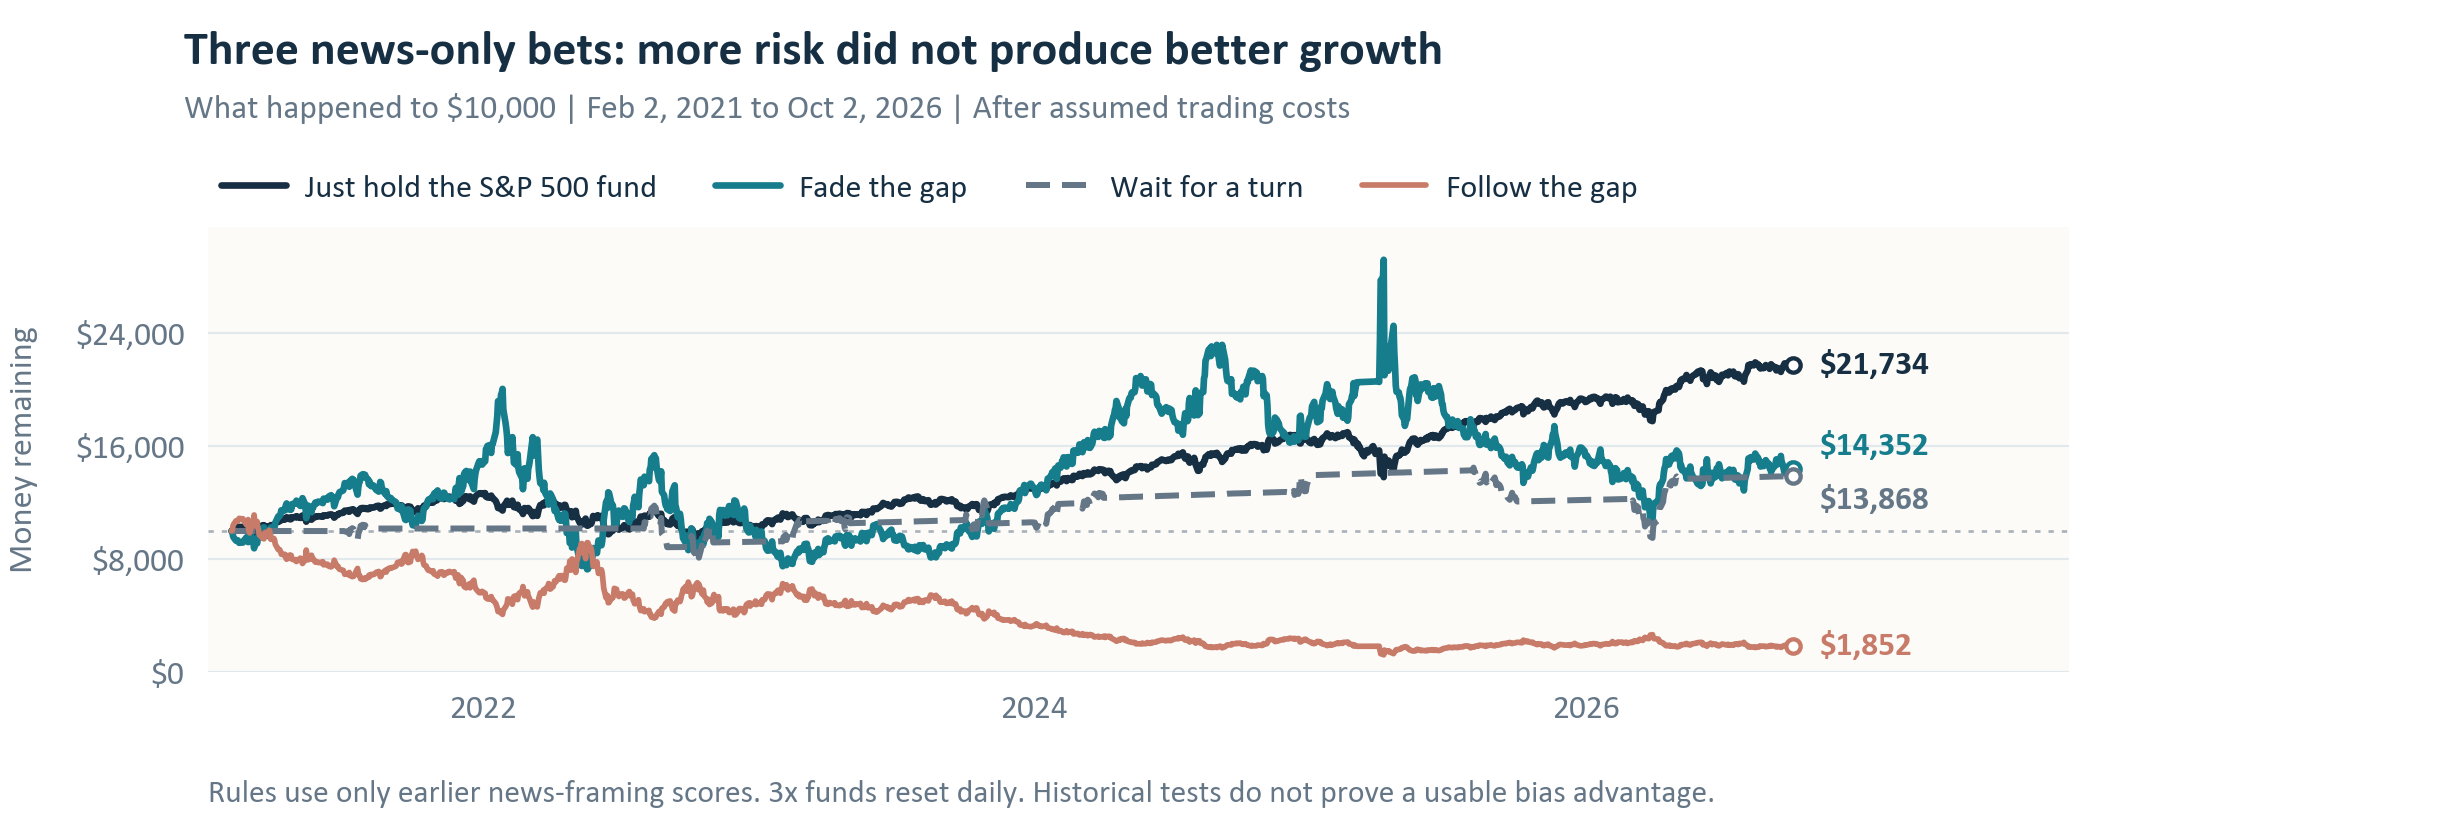

In [46]:
display(Image(filename=str(ROOT / 'outputs' / 'bias_trading.png')))

October 17, 2026 final revision, after the October 13 economic cutoff. Historical simulation: February 2, 2021 to October 2, 2026. Monthly choices use completed earlier headlines and start earning returns after execution at the first shared-session close after the first calendar day.

In [47]:
import sys
if str(ROOT / 'scripts') not in sys.path: sys.path.insert(0, str(ROOT / 'scripts'))
from study_content import sections
item = sections()[26][1][1]
display(pd.DataFrame(item['rows'], columns=item['headers']))

,Rule: same dates/costs,"End from $10,000",Yearly growth,Worst fall
0,Fade the gap,"$14,352",6.59%,63.73%
1,Follow the gap,"$1,852",-25.76%,89.07%
2,Wait for a turn,"$13,868",5.94%,34.43%
3,Hold ordinary stock fund,"$21,734",14.70%,24.50%


Costs are 0.10% per purchase or sale: $1 per $1,000 traded, charged on both legs of a switch and at entry/final exit. Gains include approximated reinvested distributions. Two rules made money, yet all three grew less and fell more than the ordinary stock fund. Waiting held bills in 55 of 68 decisions. Historical profit alone does not make these better investments.

Rules were fixed before calculating these returns, after earlier findings were known. Reconstructed headlines, later software and revised prices prevent a claim that these signals were available then. Human validation, taxes, market impact and an untouched future test are missing. Full rules and comparisons: docs/BIAS_TRADING_PROTOCOL.md; older allocation tests remain in the notebook.

No rule establishes an advantage over SPY. The three same-date mean-return tests use a Holm correction; none rejects equal mean returns at 5%. They are not alpha tests: daily leveraged exposure changes what is being compared. The notebook preserves 0, 10 and 25 basis-point cost checks, all six benchmark portfolios and the exact daily paths.

The earlier economy-and-price-trend allocation is a separate experiment: net annual growth was 5.52%, versus 9.17% for monthly 60% SPY / 40% BIL over January 2015-October 2026. The fixed mix is preferred only after this retrospective comparison. The headline gap, survey gap, matched-provider bars and price-trend signals are different quantities and are never substituted for each other.

Financial conclusion: use the monitor to question a consumer-demand narrative and stress-test a forecast. These results do not justify an aggressive position based on measured wording alone. Both profitable and losing simulations are retained, with costs and large drawdowns visible. The notebook contains the older allocation chart and full protocols; no trades were placed.

## Reproducibility and limitations

See `README.md`, `SNAPSHOT.md`, `AI_USE.md`, the source manifest, codebook, causal proposal, and annotation-validation protocol. A fresh download can change mutable feed results. Saved aggregate outputs preserve this snapshot, while item-level data remain local.